# Think on the Graph: every output of the run MY01
## 0. Input
Program:
```java
int sum = 7;
int count = 2;
double avg = (double) (sum / count);
System.out.println(avg);
```
Question: What does this program print, and why?

Student's answer: It prints 3.5. The (double) cast turns the division into a decimal division, so 7 / 2 gives 3.5 and that is stored in avg.
Settings: width 3, depth 3, prune llm, backend claude-cli, model claude-opus-5-5
## 1. Stage 1: the subgraph G from the code (no model)
Masked code (string and char literals and comments blanked; this is what the patterns see):
```
int sum = 7;
int count = 2;
double avg = (double) (sum / count);
System.out.println(avg);
```
Which code text tagged which concept (a generic concept fires on almost any Java line; it starts the walk only if the answer repeats its tag):
| concept | generic | channel | matched text | line |
|---|---|---|---|---|
| arithmetic_operators | False | pattern | 'm / c' | 3 |
| explicit_cast | False | pattern | '(double) (' | 3 |
| expression | True | pattern | 'm / c' | 3 |
| expression | True | pattern | '= 7;' | 1 |
| integer_division | False | signal | 'int sum = 7;\nint count = 2;\ndouble avg = (double) (sum / count' | 1 |
| primitive_type | True | pattern | 'int' | 1 |
| println | False | pattern | 'System.out.println(' | 4 |
| statement | True | pattern | ';' | 1 |
| type_conversion | False | pattern | '(double) (' | 3 |

G: 8 concept nodes (3 generic), 5 concept edges, 39 misconception / error edges, 34 misconception / error nodes, 40 level nodes, 49 level-misconception links, 3 connected piece(s).
Note: concept nodes form 3 pieces (the KG has no edge between them): arithmetic_operators,expression,integer_division | explicit_cast,primitive_type,type_conversion | println,statement

Concept edges of G (the links the walk can read; `pre:` = prerequisite A -> B, `par:` = parallel):
| edge | type | rule (logic) |
|---|---|---|
| pre:arithmetic_operators->expression | prerequisite | An operator combines operand values a and b into a new value, so operators build larger expressions from smaller ones. |
| pre:arithmetic_operators->integer_division | prerequisite | For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r. |
| pre:primitive_type->type_conversion | prerequisite | Conversion moves a value between primitive types: int to double happens automatically, while double to int needs a cast that drops the fraction. |
| pre:statement->println | prerequisite | System.out.println(s); is itself a statement, so its line of output appears at its own place in the sequence. |
| pre:type_conversion->explicit_cast | prerequisite | A cast is the explicit form of type conversion between primitive types, required when the conversion may lose information (e.g. (int) 2.71828 is 2). |

Misconception / error edges per concept (count), and level ways per concept (count):
| concept | misconception / error edges | level ways (L1-L4 + L0 non-misconception) |
|---|---|---|
| arithmetic_operators | 3 | 18 |
| explicit_cast | 6 | 19 |
| expression | 8 | 19 |
| integer_division | 6 | 16 |
| primitive_type | 2 | 21 |
| println | 6 | 17 |
| statement | 5 | 19 |
| type_conversion | 3 | 18 |


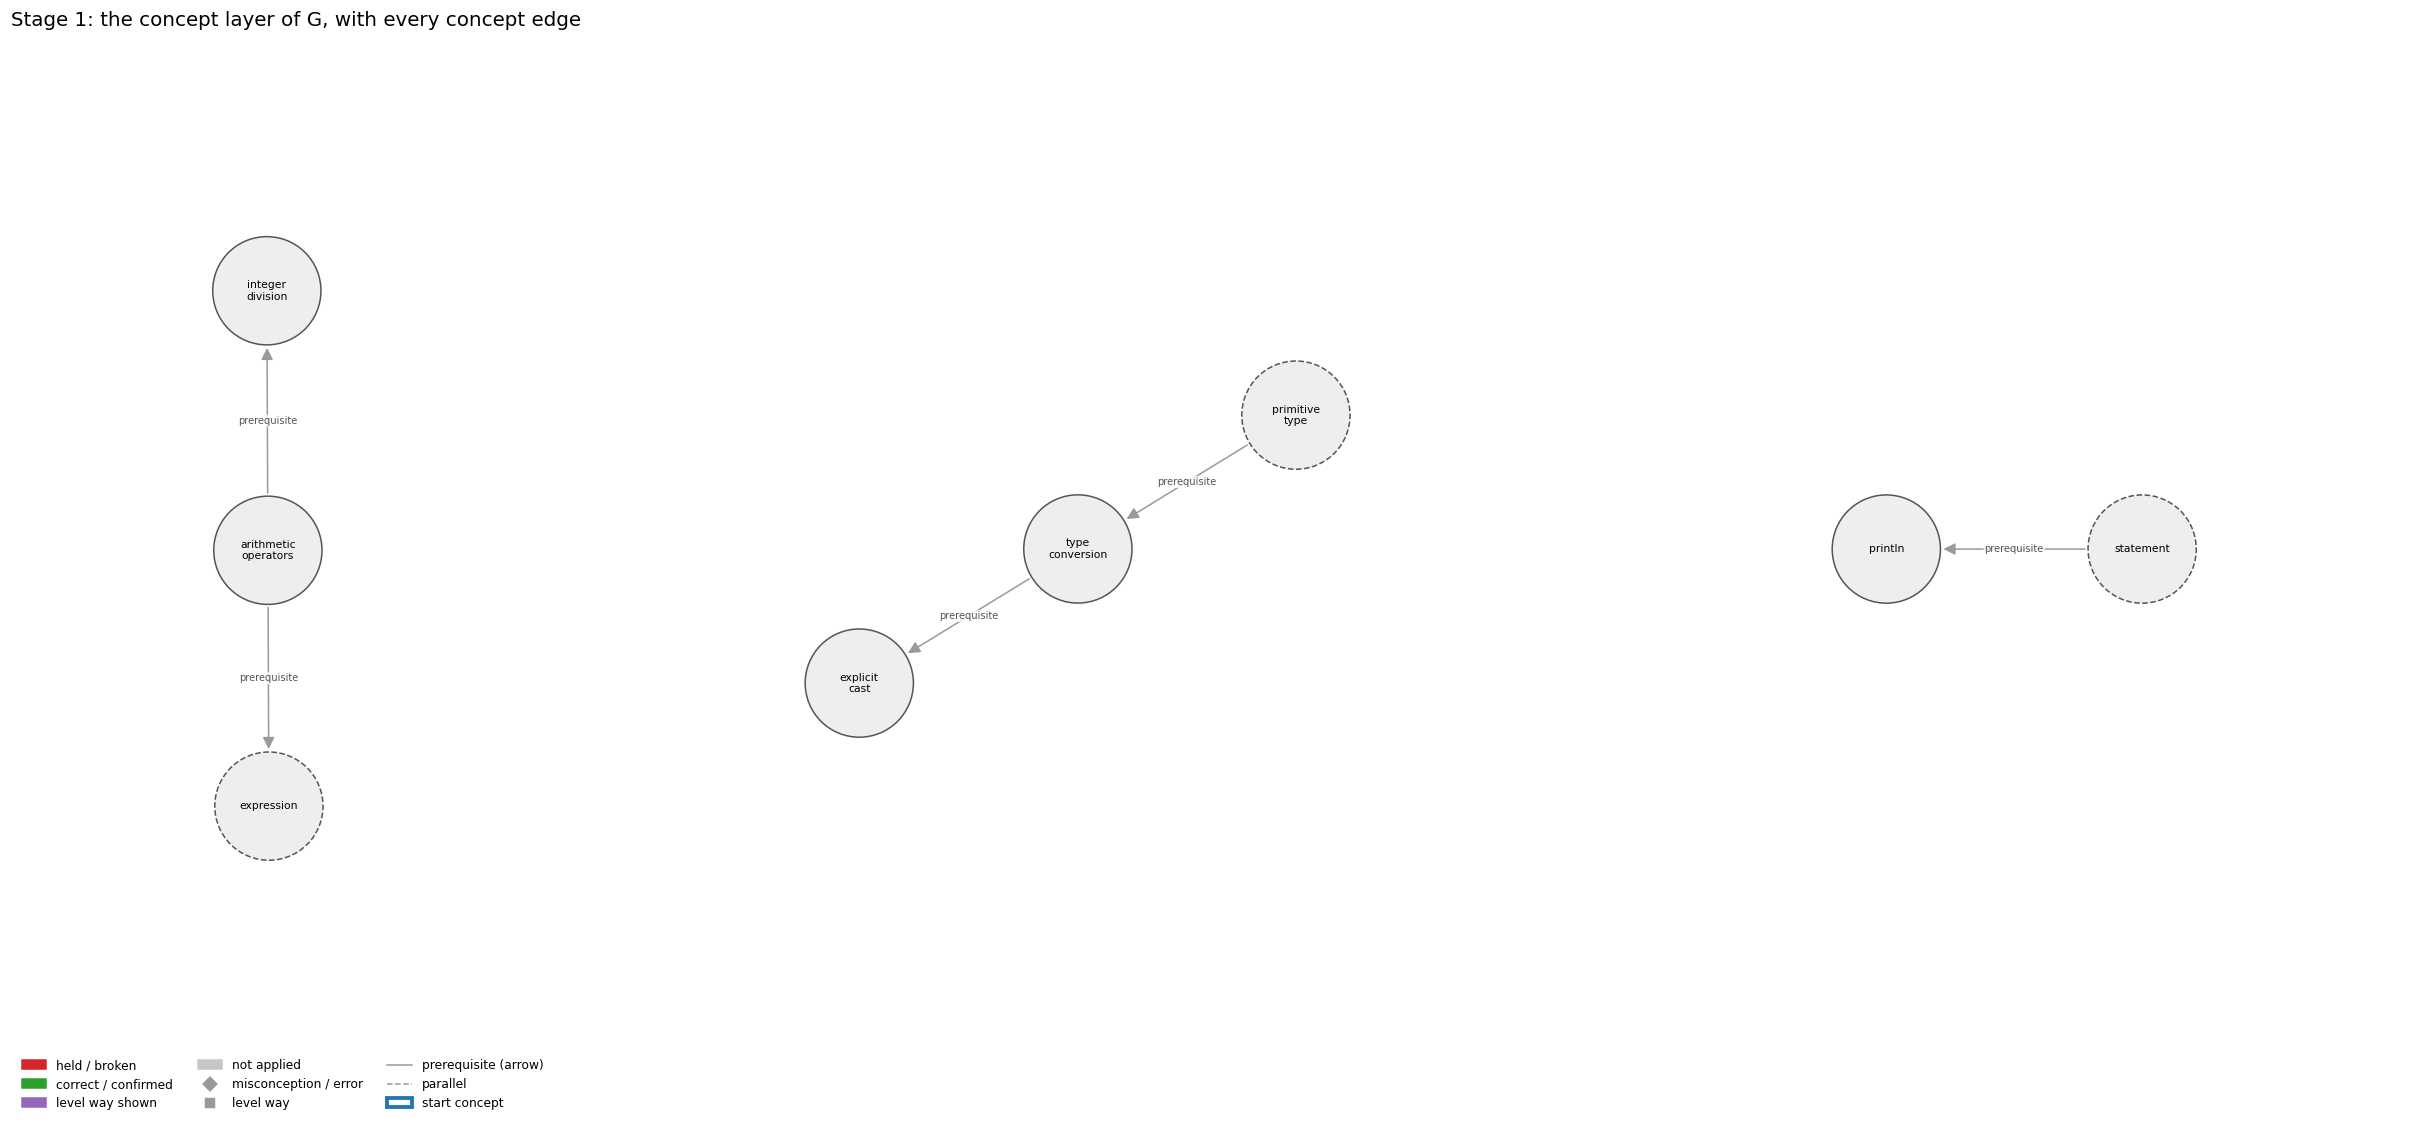

In [1]:
# Figure 1

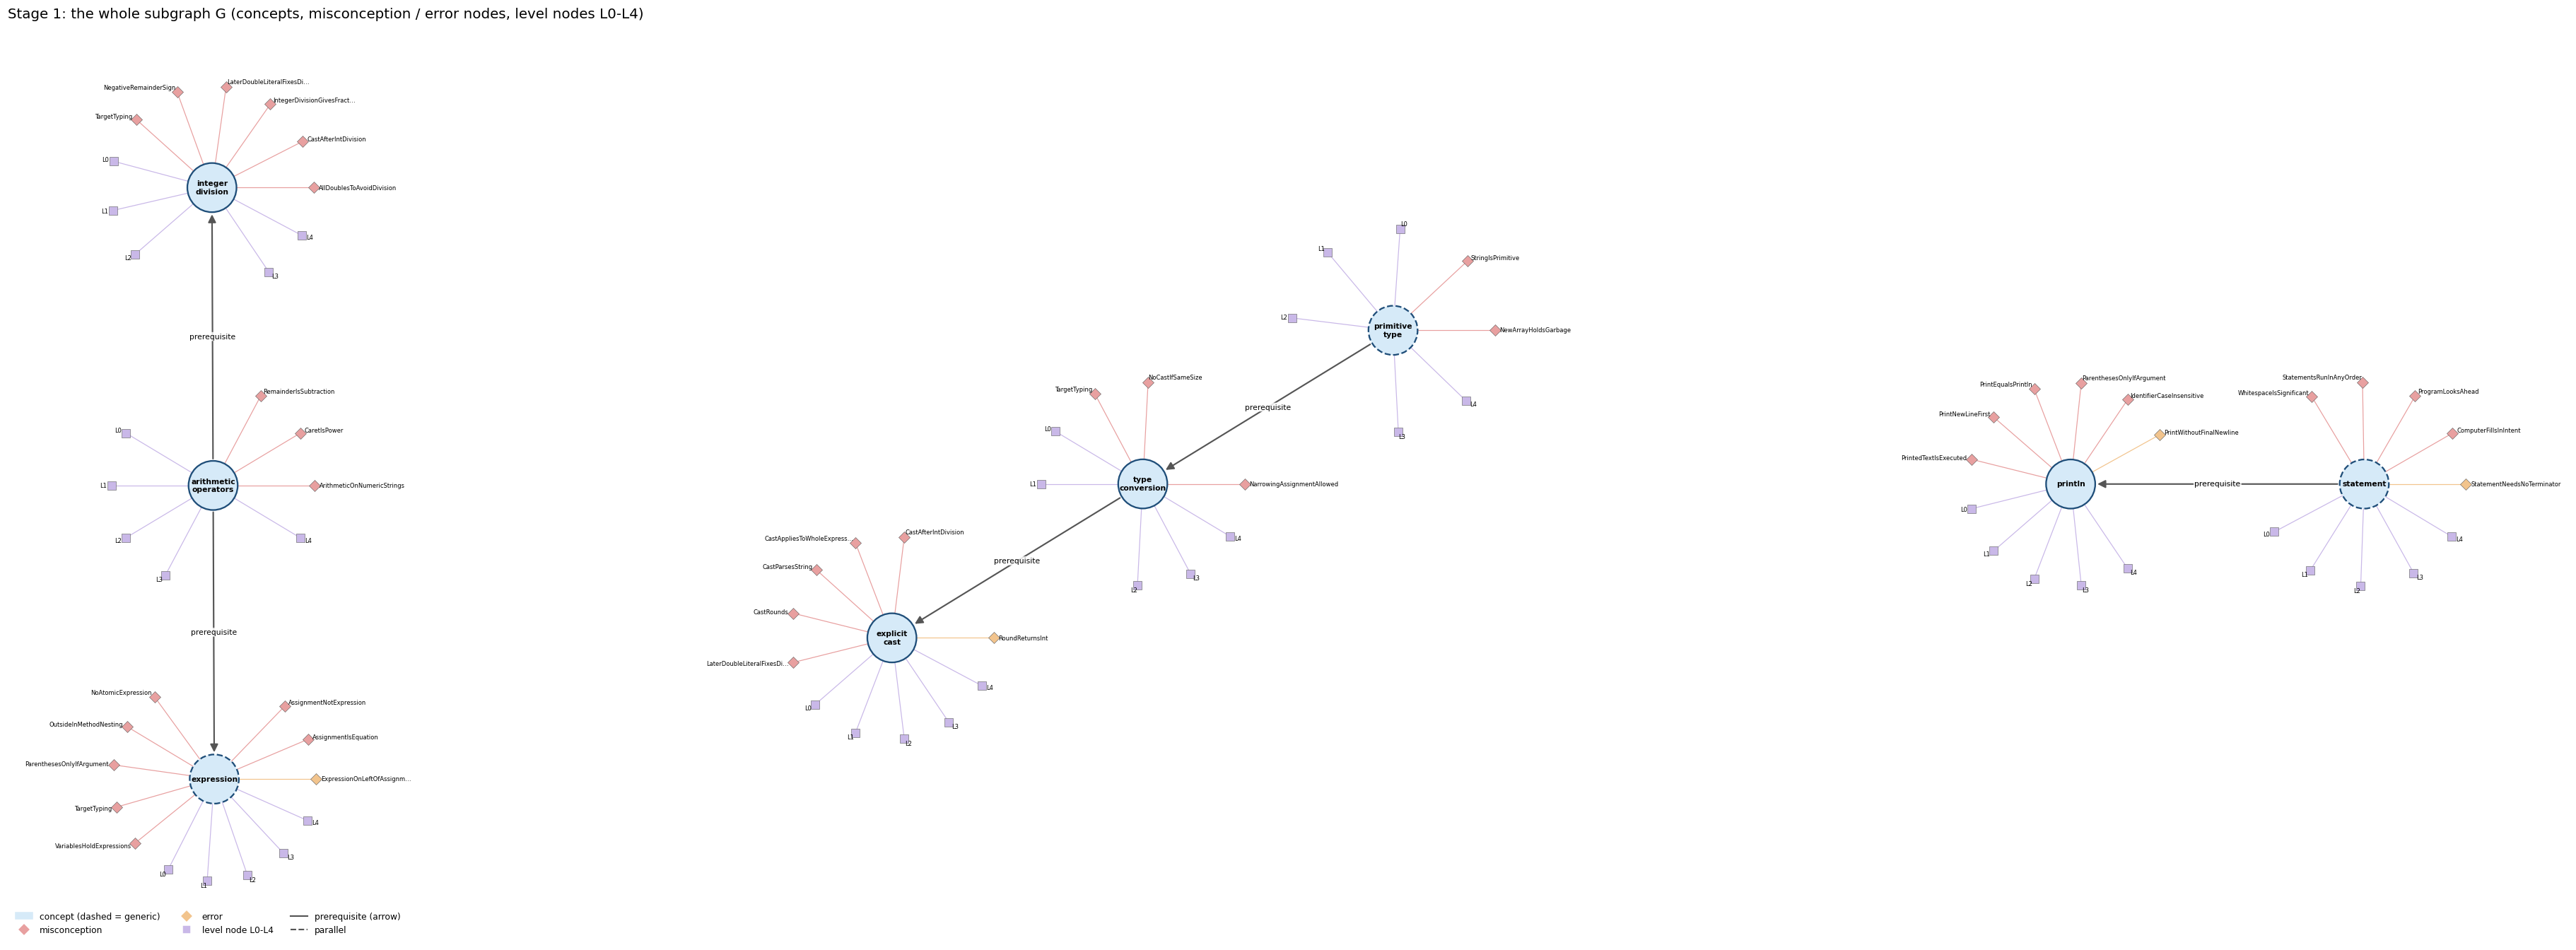

In [2]:
# Figure 2


## 2. Clauses and start concepts (no model)
The answer split into clauses (at sentence ends, ';', and before 'because' / 'so'; quotes removed):
| clause | text |
|---|---|
| c1 | It prints 3.5 |
| c2 | The (double) cast turns the division into a decimal division |
| c3 | so 7 / 2 gives 3.5 and that is stored in avg |

start: BM25 of the answer against each tagged concept: explicit_cast 15.54 (hits 1), integer_division 12.63 (hits 1), arithmetic_operators 7.88 (hits 1), println 7.20 (hits 1), type_conversion 7.08 (hits 1)

start: chosen explicit_cast, integer_division, arithmetic_operators

start concepts (3): explicit_cast, integer_division, arithmetic_operators

Start concepts: explicit_cast, integer_division, arithmetic_operators


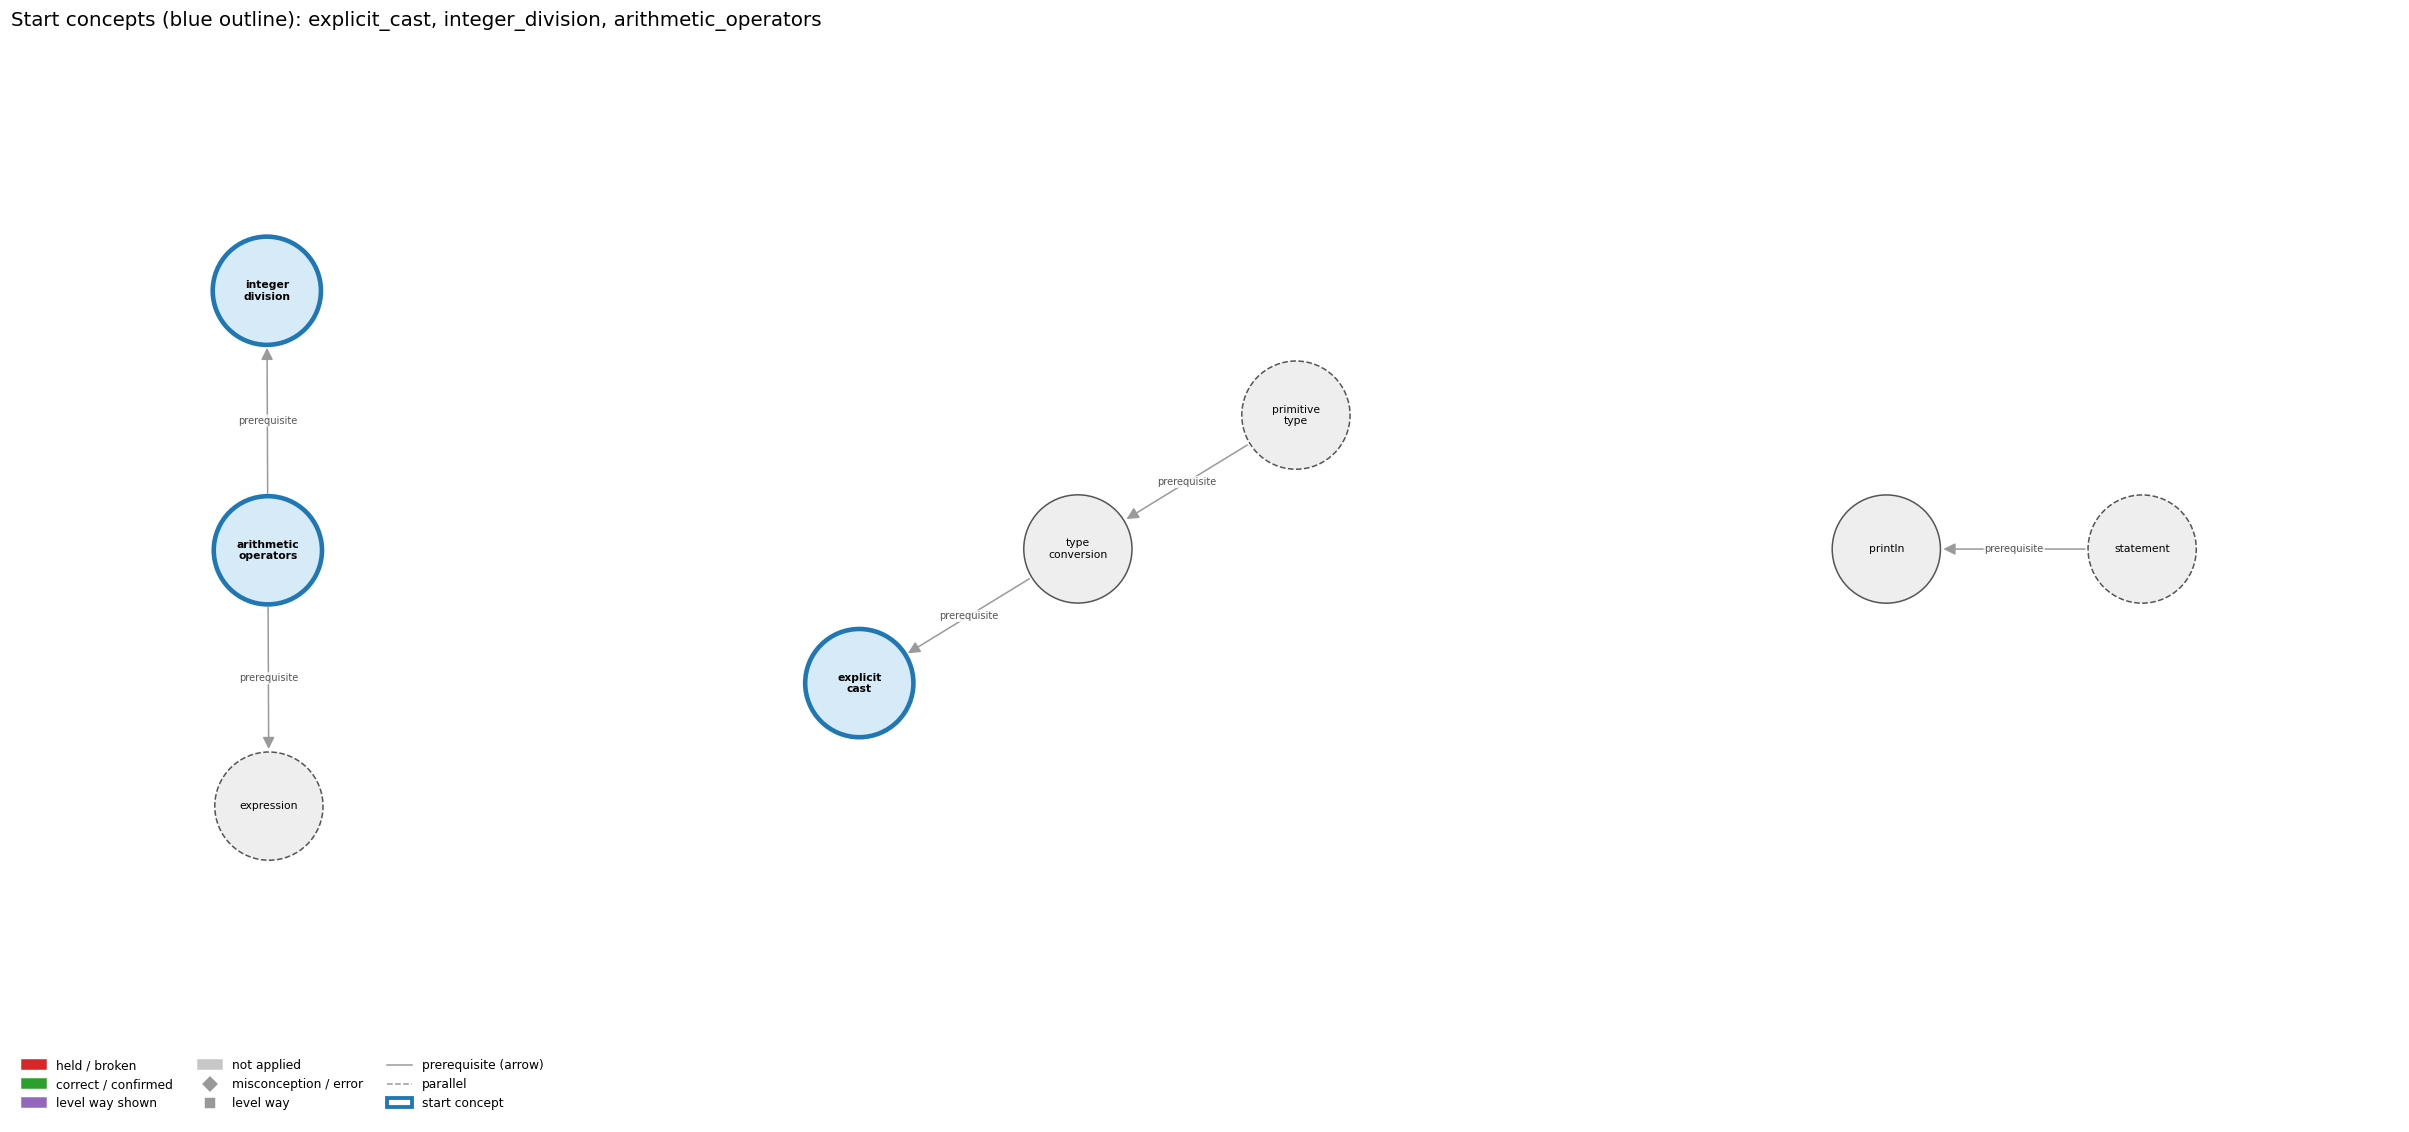

In [3]:
# Figure 3


## 3. The walk, depth by depth
At each depth, for each current concept: the edges offered (a concept entering as a start concept offers its misconception / error edges and its level ways, as two families; otherwise it offers its concept edges), the prune prompt and the model's reply, then the label prompt(s) and the model's reply, parsed into label / clauses / confidence. Score = prune score x confidence.

### Depth 1: current concepts 'explicit_cast', 'integer_division', 'arithmetic_operators'

#### explicit_cast, misconceptions: 6 edges offered
Edges offered:
| edge |
|---|
| err:explicit_cast->RoundReturnsInt \| wrong rule: Writes int n = Math.round(x); because Math.round gives an int. \| right rule: Math.round(double) returns a long, so storing it in an int needs a cast: int n = (int) Math.round(x); |
| mis:explicit_cast->CastAfterIntDivision \| wrong rule: (double) (3 / 5) is 0.6. \| right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0. |
| mis:explicit_cast->CastAppliesToWholeExpression \| wrong rule: (int) 2.5 / 0.15 casts the whole quotient to int. \| right rule: The cast applies only to what comes right after it, here 2.5. |
| mis:explicit_cast->CastParsesString \| wrong rule: (int) args[0] converts the text "34" into the number 34. \| right rule: A String argument that represents a number must be converted with a method such as Integer.parseInt. |
| mis:explicit_cast->CastRounds \| wrong rule: (int) 2.7 evaluates to 3. \| right rule: A cast to int discards the fractional part (rounds toward zero, so (int) -2.7 is -2); Math.round rounds to the nearest integer. |
| mis:explicit_cast->LaterDoubleLiteralFixesDivision \| wrong rule: Changing a later literal to 100.0 fixes an earlier int division. \| right rule: The int division happens first; the double must be in the division itself. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
mis:explicit_cast->CastAfterIntDivision (0.80), mis:explicit_cast->CastAppliesToWholeExpression (0.12), mis:explicit_cast->LaterDoubleLiteralFixesDivision (0.08)
```
Kept by pruning: mis:explicit_cast->CastAfterIntDivision (0.80), mis:explicit_cast->CastAppliesToWholeExpression (0.12), mis:explicit_cast->LaterDoubleLiteralFixesDivision (0.08)

Label prompt for the misconception / error edges (judged together). The model saw the program, the question, the numbered clauses, and these edges with their wrong rule and right rule:
| edge |
|---|
| mis:explicit_cast->CastAfterIntDivision \| wrong rule: (double) (3 / 5) is 0.6. \| right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0. |
| mis:explicit_cast->CastAppliesToWholeExpression \| wrong rule: (int) 2.5 / 0.15 casts the whole quotient to int. \| right rule: The cast applies only to what comes right after it, here 2.5. |
| mis:explicit_cast->LaterDoubleLiteralFixesDivision \| wrong rule: Changing a later literal to 100.0 fixes an earlier int division. \| right rule: The int division happens first; the double must be in the division itself. |
Model's reply:
```
mis:explicit_cast->CastAfterIntDivision | held | clauses: 1, 2, 3 | confidence: 0.95
mis:explicit_cast->CastAppliesToWholeExpression | not applied | clauses: none | confidence: 0.75
mis:explicit_cast->LaterDoubleLiteralFixesDivision | not applied | clauses: none | confidence: 0.95
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| mis:explicit_cast->CastAfterIntDivision | held | 0.8 | 0.95 | 0.76 | c1, c2, c3 | It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| mis:explicit_cast->CastAppliesToWholeExpression | not applied |  |  | 0.0 |  |  |
| mis:explicit_cast->LaterDoubleLiteralFixesDivision | not applied |  |  | 0.0 |  |  |

#### explicit_cast, level ways: 19 edges offered
Edges offered:
| edge |
|---|
| lvl:explicit_cast@L0#0 \| level L0 way everyday_reading: Folk meaning: 'convert 2.7 to a whole number' means round it to 3, and (int) looks like a function label that applies to everything written after it. Java rule: a cast to int truncates toward zero ((int) 2.7 is 2) and, having higher precedence than arithmetic, applies only to the value immediately following it. |
| lvl:explicit_cast@L0#4 \| level L0 way inconsistent_trace: Points to LT (the cast is a unary operator applied to the operand right after it, before * and /). Applied unevenly: in one line the student casts only the first operand, and in another applies the same cast to the whole expression. (here mixing in: "(int) 2.7 evaluates to 3") |
| lvl:explicit_cast@L1#0 \| level L1 way names_the_element: A cast is a unary operator, written (type) expression, that converts a value of one primitive type to another, used when the conversion may lose information. |
| lvl:explicit_cast@L1#1 \| level L1 way states_the_rule: (T) e converts the value of e to type T; a double-to-int cast discards the fraction by rounding toward zero; a cast is required for narrowing conversions; it has higher precedence than arithmetic; casts between boolean and numbers, or from String to int, are not allowed. |
| lvl:explicit_cast@L2#0 \| level L2 way line_by_line_trace: Evaluate the operand immediately to the right of the cast (a parenthesized expression is evaluated completely first), convert that value, then continue with the remaining operators of the expression. |
| lvl:explicit_cast@L2#1 \| level L2 way output_prediction: (int) 2.71828 is int 2; (int) -2.7 is -2; (int) 11 * 0.3 is double 3.3; (int) (11 * 0.3) is int 3; (double) 3 / 5 is 0.6 but (double) (3 / 5) is 0.0; (char) ('a' + 4) is 'e'. |
| lvl:explicit_cast@L2#2 \| level L2 way one_step_execution: A cast yields a new value and changes nothing else: neither the type nor the value of the variable being cast changes (after int x = (int) pi; pi is still 3.14159). |
| lvl:explicit_cast@L3#0 \| level L3 way relation_to_neighbour: A cast is the explicit conversion between primitive types, needed exactly where automatic conversion is refused because information may be lost. |
| lvl:explicit_cast@L3#1 \| level L3 way relation_to_neighbour: To turn Math.random()'s double into a random int from 0 to N-1, the cast must enclose the product: (int) (Math.random() * N); casting first gives 0. |
| lvl:explicit_cast@L3#2 \| level L3 way relation_to_neighbour: x op= e contains an implicit cast back to the type of x, so with int x, x += 0.5 compiles (x = (int) (x + 0.5)) while x = x + 0.5 is a compile-time error. |
| lvl:explicit_cast@L3#3 \| level L3 way relation_to_neighbour: Widening (promotion) happens automatically when a value goes to a type with a larger range (int to double) and loses nothing; a narrowing conversion (double to int) is never automatic and needs an explicit cast, which truncates toward zero. |
| lvl:explicit_cast@L3#4 \| level L3 way relation_to_neighbour: (int) 2.71828 truncates toward zero and gives 2; Math.round(2.71828) rounds to the nearest integer and gives 3, as a long that needs (int) to become an int. |
| lvl:explicit_cast@L3#5 \| level L3 way purpose_of_the_whole: Used to discard information on purpose: truncating a scaled random number to an index, taking the integer part, converting between char and int codes ((char) ('a' + k)), or forcing real division with (double) sum / n. |
| lvl:explicit_cast@L4#0 \| level L4 way predict_a_change: Moving the parentheses changes when truncation happens ((int) (a * b) vs (int) a * b); removing a cast from a narrowing assignment turns it into a compile-time error; int to double to int restores the value, but double to int to double loses the fraction. |
| lvl:explicit_cast@L4#1 \| level L4 way transfer_to_a_new_program: Use a cast when you intend to truncate or narrow (random indices, integer parts, char codes); use Math.round to round, Integer.parseInt for Strings, and put a double into the division itself rather than casting its int result. |
| lvl:explicit_cast@L4#2 \| level L4 way diagnose_an_error: rule broken: Math.round(double) returns a long, so storing it in an int needs a cast: int n = (int) Math.round(x);. Kind: compile-time. Trigger class: int n = Math.round(x); with double x. |
| lvl:explicit_cast@L4#3 \| level L4 way diagnose_an_error: rule broken: A cast applies only to the value right after it. Kind: compile-time. Trigger class: int n = (int) 11 * 0.3; the product is still a double (possible loss of precision); in a double context the same mistake is a silent logic error ((int) pi * 20.0 gives 60.0). |
| lvl:explicit_cast@L4#4 \| level L4 way diagnose_an_error: rule broken: Casts require compatible types. Kind: compile-time. Trigger class: (int) "3" or (int) args[0] on a String, or a cast between boolean and a number. |
| lvl:explicit_cast@L4#5 \| level L4 way diagnose_an_error: rule broken: A narrowing cast may lose magnitude, not just the fraction. Kind: silent logic error. Trigger class: Casting a value outside the target range, e.g. (int) of a long above 2147483647 or of a huge double. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{lvl:explicit_cast@L2#1 (Score: 0.45)}
{lvl:explicit_cast@L2#0 (Score: 0.35)}
{lvl:explicit_cast@L4#1 (Score: 0.2)}
```
Kept by pruning: lvl:explicit_cast@L2#1 (0.45), lvl:explicit_cast@L2#0 (0.35), lvl:explicit_cast@L4#1 (0.20)

Label prompt for level way lvl:explicit_cast@L2#1 (the model saw only the concept, the way's name 'output prediction' and its text; no level):
> (int) 2.71828 is int 2; (int) -2.7 is -2; (int) 11 * 0.3 is double 3.3; (int) (11 * 0.3) is int 3; (double) 3 / 5 is 0.6 but (double) (3 / 5) is 0.0; (char) ('a' + 4) is 'e'.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.95
```

Label prompt for level way lvl:explicit_cast@L2#0 (the model saw only the concept, the way's name 'line by line trace' and its text; no level):
> Evaluate the operand immediately to the right of the cast (a parenthesized expression is evaluated completely first), convert that value, then continue with the remaining operators of the expression.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.95
```

Label prompt for level way lvl:explicit_cast@L4#1 (the model saw only the concept, the way's name 'transfer to a new program' and its text; no level):
> Use a cast when you intend to truncate or narrow (random indices, integer parts, char codes); use Math.round to round, Integer.parseInt for Strings, and put a double into the division itself rather than casting its int result.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.95
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| lvl:explicit_cast@L2#1 | not applied |  |  | 0.0 |  |  |
| lvl:explicit_cast@L2#0 | not applied |  |  | 0.0 |  |  |
| lvl:explicit_cast@L4#1 | not applied |  |  | 0.0 |  |  |

#### integer_division, misconceptions: 6 edges offered
Edges offered:
| edge |
|---|
| mis:integer_division->AllDoublesToAvoidDivision \| wrong rule: Making every variable a double is the right fix for integer division. \| right rule: Use int for countable things and double for measured ones; where a fraction is needed, make one operand of the division a double (or cast) instead of changing every type. |
| mis:integer_division->CastAfterIntDivision \| wrong rule: (double) (3 / 5) is 0.6. \| right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0. |
| mis:integer_division->IntegerDivisionGivesFraction \| wrong rule: 10 / 3 evaluates to 3.333.... \| right rule: Dividing two ints gives an int: the fractional part is discarded. |
| mis:integer_division->LaterDoubleLiteralFixesDivision \| wrong rule: Changing a later literal to 100.0 fixes an earlier int division. \| right rule: The int division happens first; the double must be in the division itself. |
| mis:integer_division->NegativeRemainderSign \| wrong rule: a % b is never negative, and integer division of a negative number rounds down. \| right rule: a / b rounds toward 0 and a % b takes the sign of a: -14 / 3 is -4 and -14 % 3 is -2. |
| mis:integer_division->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
mis:integer_division->CastAfterIntDivision (0.70), mis:integer_division->IntegerDivisionGivesFraction (0.20), mis:integer_division->TargetTyping (0.10)
```
Kept by pruning: mis:integer_division->CastAfterIntDivision (0.70), mis:integer_division->IntegerDivisionGivesFraction (0.20), mis:integer_division->TargetTyping (0.10)

Label prompt for the misconception / error edges (judged together). The model saw the program, the question, the numbered clauses, and these edges with their wrong rule and right rule:
| edge |
|---|
| mis:integer_division->CastAfterIntDivision \| wrong rule: (double) (3 / 5) is 0.6. \| right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0. |
| mis:integer_division->IntegerDivisionGivesFraction \| wrong rule: 10 / 3 evaluates to 3.333.... \| right rule: Dividing two ints gives an int: the fractional part is discarded. |
| mis:integer_division->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |
Model's reply:
```
mis:integer_division->CastAfterIntDivision | held | clauses: 2, 3 | confidence: 0.95
mis:integer_division->IntegerDivisionGivesFraction | not applied | clauses: none | confidence: 0.8
mis:integer_division->TargetTyping | not applied | clauses: none | confidence: 0.85
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| mis:integer_division->CastAfterIntDivision | held | 0.7000000000000001 | 0.95 | 0.67 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| mis:integer_division->IntegerDivisionGivesFraction | not applied |  |  | 0.0 |  |  |
| mis:integer_division->TargetTyping | not applied |  |  | 0.0 |  |  |

#### integer_division, level ways: 16 edges offered
Edges offered:
| edge |
|---|
| lvl:integer_division@L0#0 \| level L0 way everyday_reading: In everyday and school arithmetic, 'divide' gives an exact answer or a fraction (10 ÷ 3 = 3 1/3), and rounding goes to the nearest whole number. In Java, / with two int operands discards the fraction, rounding toward zero (59 / 60 is 0). |
| lvl:integer_division@L0#4 \| level L0 way inconsistent_trace: Points to LT (each / looks at its own two operand types when it is evaluated). Applied unevenly, a student evaluates 9/5 as 1.8 in f = (9/5)*c + 32 but as 1 elsewhere, or assumes a later double operand rescues an earlier int division. (here mixing in: "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction") |
| lvl:integer_division@L1#0 \| level L1 way names_the_element: Integer division: / applied to two integer operands, giving the whole-number quotient with the fractional part discarded. |
| lvl:integer_division@L1#1 \| level L1 way states_the_rule: If both operands of / are integral types, the result is an integer that rounds toward 0 (-14 / 3 is -4). If either operand is a double, the division is floating point. |
| lvl:integer_division@L2#0 \| level L2 way line_by_line_trace: Each / is evaluated when its turn comes (precedence, then left to right), using the types of its own two operands. Promoting the result to double, by a cast or by assignment, happens only afterwards and cannot restore the lost fraction. |
| lvl:integer_division@L2#1 \| level L2 way output_prediction: 10 / 3 is 3, 59 / 60 is 0, 1234 / 99 is 12, -14 / 3 is -4, and (double) (3 / 5) is 0.0. |
| lvl:integer_division@L2#2 \| level L2 way one_step_execution: q = a / b stores the truncated quotient in q and leaves a and b unchanged. If b is 0, an ArithmeticException stops execution before anything is stored. |
| lvl:integer_division@L3#0 \| level L3 way relation_to_neighbour: / and % on ints are paired: q = a / b and r = a % b always satisfy a = b * q + r. |
| lvl:integer_division@L3#1 \| level L3 way relation_to_neighbour: Normalizing counts must divide as doubles. With two ints, counts / total truncates to 0 whenever counts < total. |
| lvl:integer_division@L3#2 \| level L3 way relation_to_neighbour: % gives the remainder of the same truncating division: (a / b) * b + a % b == a. |
| lvl:integer_division@L3#3 \| level L3 way purpose_of_the_whole: Quotient plans: unit conversion (76 / 12 feet), dropping a digit (n / 10), finding a midpoint ((lo + hi) / 2), and computing a bucket or row index (i / cols). |
| lvl:integer_division@L4#0 \| level L4 way predict_a_change: Making one operand a double (10.0 / 3) keeps the fraction (3.333...). Casting after the division does not. Multiplying before dividing preserves precision (59 * 100 / 60 is 98). Changing an operand's sign changes only the quotient's sign, since rounding is toward zero. |
| lvl:integer_division@L4#1 \| level L4 way transfer_to_a_new_program: Use integer division when you want the whole quotient (units, digits, indices, half a size). When a fraction is needed, make one operand a double (10.0 / 3 or (double) a / b) rather than turning every variable into a double. |
| lvl:integer_division@L4#2 \| level L4 way diagnose_an_error: rule broken: With two int operands, / discards the fraction. Kind: silent logic error. Trigger class: Two int operands where a fraction is intended: 9/5 in a temperature formula, count / total, 1 / n, sum / n for an average. |
| lvl:integer_division@L4#3 \| level L4 way diagnose_an_error: rule broken: int division by zero is undefined. Kind: run-time exception. Trigger class: A divisor that evaluates to 0: ArithmeticException: / by zero. |
| lvl:integer_division@L4#4 \| level L4 way diagnose_an_error: rule broken: Integer division rounds toward zero, not down. Kind: silent logic error. Trigger class: Negative operands where floor was expected (-7 / 2 is -3, not -4). |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{lvl:integer_division@L0#4 (Score: 0.5)}
{lvl:integer_division@L2#0 (Score: 0.3)}
{lvl:integer_division@L0#0 (Score: 0.2)}
```
Kept by pruning: lvl:integer_division@L0#4 (0.50), lvl:integer_division@L2#0 (0.30), lvl:integer_division@L0#0 (0.20)

Label prompt for level way lvl:integer_division@L0#4 (the model saw only the concept, the way's name 'inconsistent trace' and its text; no level):
> Points to LT (each / looks at its own two operand types when it is evaluated). Applied unevenly, a student evaluates 9/5 as 1.8 in f = (9/5)*c + 32 but as 1 elsewhere, or assumes a later double operand rescues an earlier int division. (here mixing in: "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction")

Model's reply:
```
Label: shown
Clauses: 2, 3
Confidence: 0.85
```

Label prompt for level way lvl:integer_division@L2#0 (the model saw only the concept, the way's name 'line by line trace' and its text; no level):
> Each / is evaluated when its turn comes (precedence, then left to right), using the types of its own two operands. Promoting the result to double, by a cast or by assignment, happens only afterwards and cannot restore the lost fraction.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.97
```

Label prompt for level way lvl:integer_division@L0#0 (the model saw only the concept, the way's name 'everyday reading' and its text; no level):
> In everyday and school arithmetic, 'divide' gives an exact answer or a fraction (10 ÷ 3 = 3 1/3), and rounding goes to the nearest whole number. In Java, / with two int operands discards the fraction, rounding toward zero (59 / 60 is 0).

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.85
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| lvl:integer_division@L0#4 | shown | 0.5 | 0.85 | 0.42 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| lvl:integer_division@L2#0 | not applied |  |  | 0.0 |  |  |
| lvl:integer_division@L0#0 | not applied |  |  | 0.0 |  |  |

#### arithmetic_operators, misconceptions: 3 edges offered
Edges offered:
| edge |
|---|
| mis:arithmetic_operators->ArithmeticOnNumericStrings \| wrong rule: "10" - 1 or "6" * "2" works because the strings look like numbers. \| right rule: Arithmetic operators other than + are not defined for Strings; a String of digits must first be converted to a number, e.g. with Integer.parseInt. |
| mis:arithmetic_operators->CaretIsPower \| wrong rule: a^2 computes a squared. \| right rule: Java has no exponent operator; ^ is exclusive or, and a * a or Math.pow(a, 2) computes a squared. |
| mis:arithmetic_operators->RemainderIsSubtraction \| wrong rule: 9 % 5 means 9 minus 5 (a % b subtracts b from a). \| right rule: % gives the remainder after integer division: 9 % 5 is 4 because 9 = 1 * 5 + 4, and 17 % 5 is 2, not 12. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```

```
Kept by pruning: 

Parsed labels:
(none)

#### arithmetic_operators, level ways: 18 edges offered
Edges offered:
| edge |
|---|
| lvl:arithmetic_operators@L0#0 \| level L0 way everyday_reading: In maths notation, multiplication can be implicit (2x), ^ or a superscript means a power, ÷ is exact division, and % means percent. In Java * must be written, / depends on the operand types, % is the remainder, and there is no power operator (^ is exclusive or). |
| lvl:arithmetic_operators@L0#2 \| level L0 way inconsistent_trace: Points to LT (evaluate operands, then apply the operator in the promoted type). Applied unevenly, a student uses integer division for one / and real division for another / in the same int expression. (here mixing in: "a^2 computes a squared") |
| lvl:arithmetic_operators@L1#0 \| level L1 way names_the_element: Arithmetic operators: the binary operators + - * / % that combine two numeric operands into a numeric result. |
| lvl:arithmetic_operators@L1#1 \| level L1 way states_the_rule: Both operands must be numeric, and the result has the promoted type (int, long or double). * / % bind tighter than + -, all group left to right, and int / or % by zero throws ArithmeticException. Unary minus negates its operand (-x) and unary plus leaves it unchanged; they bind more tightly than * and /, so -a * b is (-a) * b. |
| lvl:arithmetic_operators@L2#0 \| level L2 way line_by_line_trace: The left operand is evaluated fully, then the right operand, and then the operator is applied in the promoted type. |
| lvl:arithmetic_operators@L2#1 \| level L2 way output_prediction: With ints, 17 / 3 is 5 and 17 % 3 is 2. With doubles, 5.0 / 3.0 is 1.6666666666666667. With mixed operands, the int is promoted first (10 / 3.0 is 3.333...). |
| lvl:arithmetic_operators@L2#2 \| level L2 way one_step_execution: An arithmetic operator never changes its operands. Each variable is replaced by its value, and only an assignment (or ++ or op=) stores the result. |
| lvl:arithmetic_operators@L3#0 \| level L3 way relation_to_neighbour: Operators build larger expressions from smaller ones, and each operand can itself be any expression. |
| lvl:arithmetic_operators@L3#1 \| level L3 way relation_to_neighbour: For ints, / gives the truncated quotient and % the remainder, so (a / b) * b + a % b == a. |
| lvl:arithmetic_operators@L3#2 \| level L3 way relation_to_neighbour: int / or % by zero throws a run-time exception, while floating-point division by zero gives Infinity or NaN. |
| lvl:arithmetic_operators@L3#3 \| level L3 way relation_to_neighbour: + adds when both operands are numbers and concatenates when either operand is a String, converting the other operand to a String. It is left-associative, so 1 + 2 + "3" is "33" but "1" + 2 + 3 is "123". |
| lvl:arithmetic_operators@L3#4 \| level L3 way purpose_of_the_whole: Arithmetic operators turn formulas into code: totals, averages, unit conversions (inch * CM_PER_INCH), and digit extraction (n % 10, n / 10). |
| lvl:arithmetic_operators@L4#0 \| level L4 way predict_a_change: Changing an operand's type changes the operator's meaning (int / versus double /). Reordering * and / changes integer results (59 * 100 / 60 is 98, 59 / 60 * 100 is 0). Replacing ^ with Math.pow gives a real power. |
| lvl:arithmetic_operators@L4#1 \| level L4 way transfer_to_a_new_program: Use the operators for arithmetic on numeric types. Use the Math library for powers, roots and absolute values, and parse numeric Strings before computing with them. |
| lvl:arithmetic_operators@L4#2 \| level L4 way diagnose_an_error: rule broken: int / and % by zero are undefined. Kind: run-time exception. Trigger class: A divisor that evaluates to 0 (empty count, zero input): ArithmeticException: / by zero. |
| lvl:arithmetic_operators@L4#3 \| level L4 way diagnose_an_error: rule broken: Arithmetic operators other than + are not defined for Strings. Kind: compile-time. Trigger class: "10" - 1 or "6" * "2": 'bad operand types for binary operator'. |
| lvl:arithmetic_operators@L4#4 \| level L4 way diagnose_an_error: rule broken: ^ is not exponentiation. Kind: silent logic error. Trigger class: Writing x^2 or 10^6 for a power (10^6 is 12). |
| lvl:arithmetic_operators@L4#5 \| level L4 way diagnose_an_error: rule broken: int arithmetic wraps silently on overflow. Kind: silent logic error. Trigger class: Results outside the int range. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{lvl:arithmetic_operators@L2#1 (Score: 0.5)}
{lvl:arithmetic_operators@L4#0 (Score: 0.3)}
{lvl:arithmetic_operators@L2#0 (Score: 0.2)}
```
Kept by pruning: lvl:arithmetic_operators@L2#1 (0.50), lvl:arithmetic_operators@L4#0 (0.30), lvl:arithmetic_operators@L2#0 (0.20)

Label prompt for level way lvl:arithmetic_operators@L2#1 (the model saw only the concept, the way's name 'output prediction' and its text; no level):
> With ints, 17 / 3 is 5 and 17 % 3 is 2. With doubles, 5.0 / 3.0 is 1.6666666666666667. With mixed operands, the int is promoted first (10 / 3.0 is 3.333...).

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.93
```

Label prompt for level way lvl:arithmetic_operators@L4#0 (the model saw only the concept, the way's name 'predict a change' and its text; no level):
> Changing an operand's type changes the operator's meaning (int / versus double /). Reordering * and / changes integer results (59 * 100 / 60 is 98, 59 / 60 * 100 is 0). Replacing ^ with Math.pow gives a real power.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.75
```

Label prompt for level way lvl:arithmetic_operators@L2#0 (the model saw only the concept, the way's name 'line by line trace' and its text; no level):
> The left operand is evaluated fully, then the right operand, and then the operator is applied in the promoted type.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.85
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| lvl:arithmetic_operators@L2#1 | not applied |  |  | 0.0 |  |  |
| lvl:arithmetic_operators@L4#0 | not applied |  |  | 0.0 |  |  |
| lvl:arithmetic_operators@L2#0 | not applied |  |  | 0.0 |  |  |

**Kept on a path at this depth** (best N in tiers: held misconception / broken edge, then held error, then correct / confirmed / shown):

mis:explicit_cast->CastAfterIntDivision [held, tier 0, 0.76], mis:integer_division->CastAfterIntDivision [held, tier 0, 0.67], lvl:integer_division@L0#4 [shown, tier 2, 0.42]

**Clause coverage after this depth:**
| clause | text | covered by |
|---|---|---|
| c1 | It prints 3.5 | mis:explicit_cast->CastAfterIntDivision |
| c2 | The (double) cast turns the division into a decimal division | mis:explicit_cast->CastAfterIntDivision |
| c3 | so 7 / 2 gives 3.5 and that is stored in avg | mis:explicit_cast->CastAfterIntDivision |

**Graph check, not yet read (the walk may not stop while these remain):** pre:arithmetic_operators->expression, pre:arithmetic_operators->integer_division, pre:type_conversion->explicit_cast


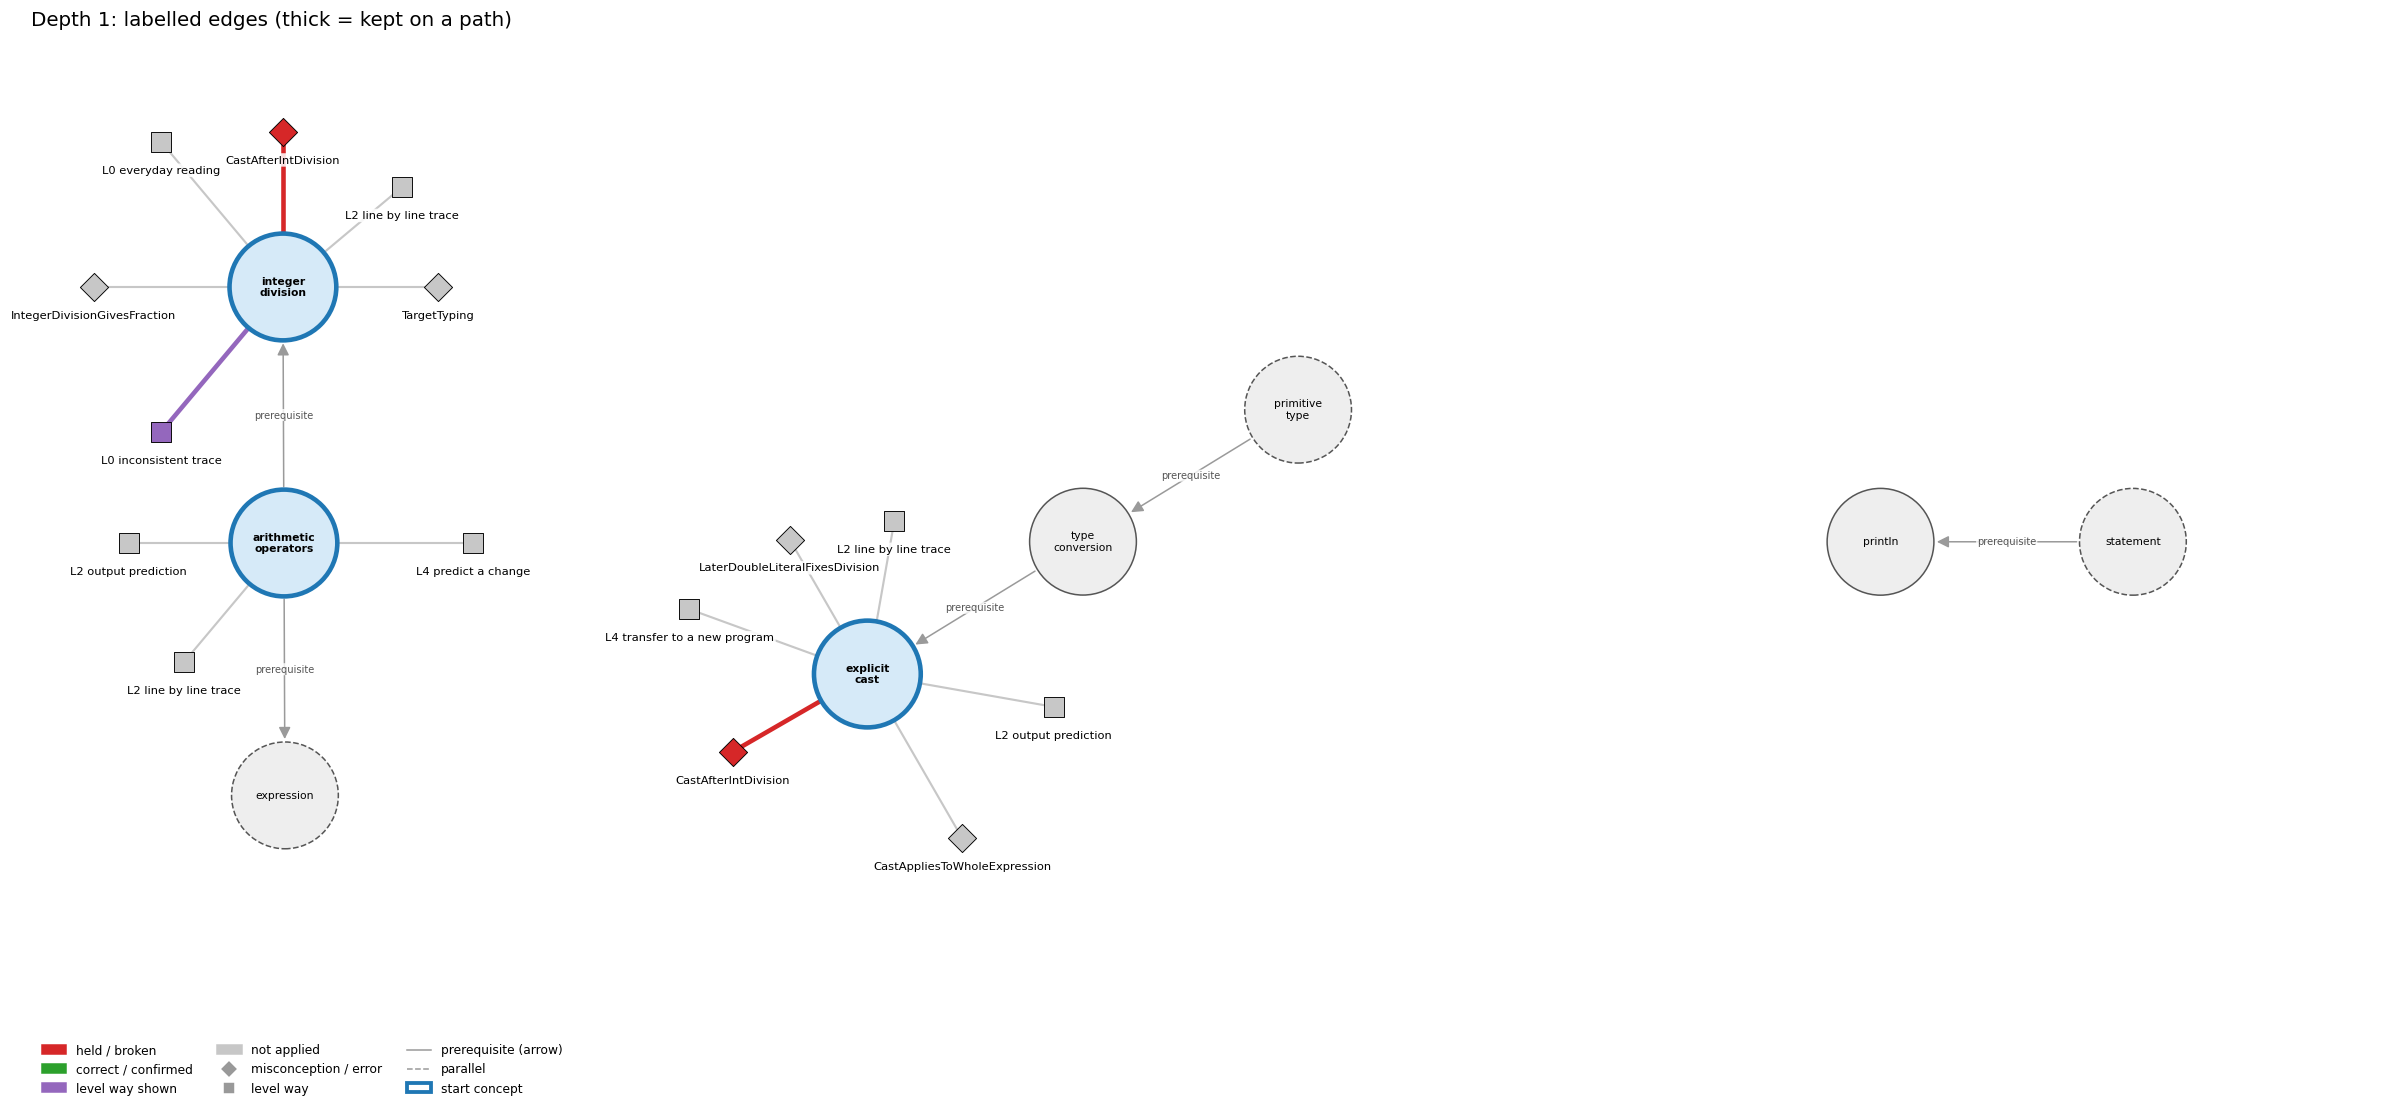

In [4]:
# Figure 4


### Depth 2: current concepts 'explicit_cast', 'integer_division', 'arithmetic_operators'

#### explicit_cast, concept edges: 1 edges offered
Edges offered:
| edge |
|---|
| pre:type_conversion->explicit_cast \| rule: A cast is the explicit form of type conversion between primitive types, required when the conversion may lose information (e.g. (int) 2.71828 is 2). |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{pre:type_conversion->explicit_cast (Score: 1.0)}
```
Kept by pruning: pre:type_conversion->explicit_cast (1.00)

Label prompt for concept edge pre:type_conversion->explicit_cast (type_conversion -> explicit_cast, prerequisite):
> A cast is the explicit form of type conversion between primitive types, required when the conversion may lose information (e.g. (int) 2.71828 is 2).

Model's reply:
```
Label: broken
Clauses: 2, 3
Confidence: 0.8
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| pre:type_conversion->explicit_cast | broken | 1.0 | 0.8 | 0.8 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |

#### integer_division, concept edges: 1 edges offered
Edges offered:
| edge |
|---|
| pre:arithmetic_operators->integer_division \| rule: For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{pre:arithmetic_operators->integer_division (Score: 1.0)}
```
Kept by pruning: pre:arithmetic_operators->integer_division (1.00)

Label prompt for concept edge pre:arithmetic_operators->integer_division (arithmetic_operators -> integer_division, prerequisite):
> For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r.

Model's reply:
```
Label: broken
Clauses: 2, 3
Confidence: 0.95
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| pre:arithmetic_operators->integer_division | broken | 1.0 | 0.95 | 0.95 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |

#### arithmetic_operators, concept edges: 1 edges offered
Edges offered:
| edge |
|---|
| pre:arithmetic_operators->expression \| rule: An operator combines operand values a and b into a new value, so operators build larger expressions from smaller ones. |
| pre:arithmetic_operators->integer_division \| rule: For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{pre:arithmetic_operators->expression (Score: 1.0)}
```
Kept by pruning: pre:arithmetic_operators->expression (1.00)

Label prompt for concept edge pre:arithmetic_operators->expression (arithmetic_operators -> expression, prerequisite):
> An operator combines operand values a and b into a new value, so operators build larger expressions from smaller ones.

Model's reply:
```
Label: confirmed
Clauses: 3
Confidence: 0.6
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| pre:arithmetic_operators->expression | confirmed | 1.0 | 0.6 | 0.6 | c3 | so 7 / 2 gives 3.5 and that is stored in avg |

**Kept on a path at this depth** (best N in tiers: held misconception / broken edge, then held error, then correct / confirmed / shown):

pre:arithmetic_operators->integer_division [broken, tier 0, 0.95], pre:type_conversion->explicit_cast [broken, tier 0, 0.80], pre:arithmetic_operators->expression [confirmed, tier 2, 0.60]

reached across pre:type_conversion->explicit_cast, entered next: type_conversion

reached across pre:arithmetic_operators->expression, entered next: expression

**Clause coverage after this depth:**
| clause | text | covered by |
|---|---|---|
| c1 | It prints 3.5 | mis:explicit_cast->CastAfterIntDivision |
| c2 | The (double) cast turns the division into a decimal division | mis:explicit_cast->CastAfterIntDivision |
| c3 | so 7 / 2 gives 3.5 and that is stored in avg | mis:explicit_cast->CastAfterIntDivision |

**Graph check, not yet read (the walk may not stop while these remain):** own edges of expression, own edges of type_conversion


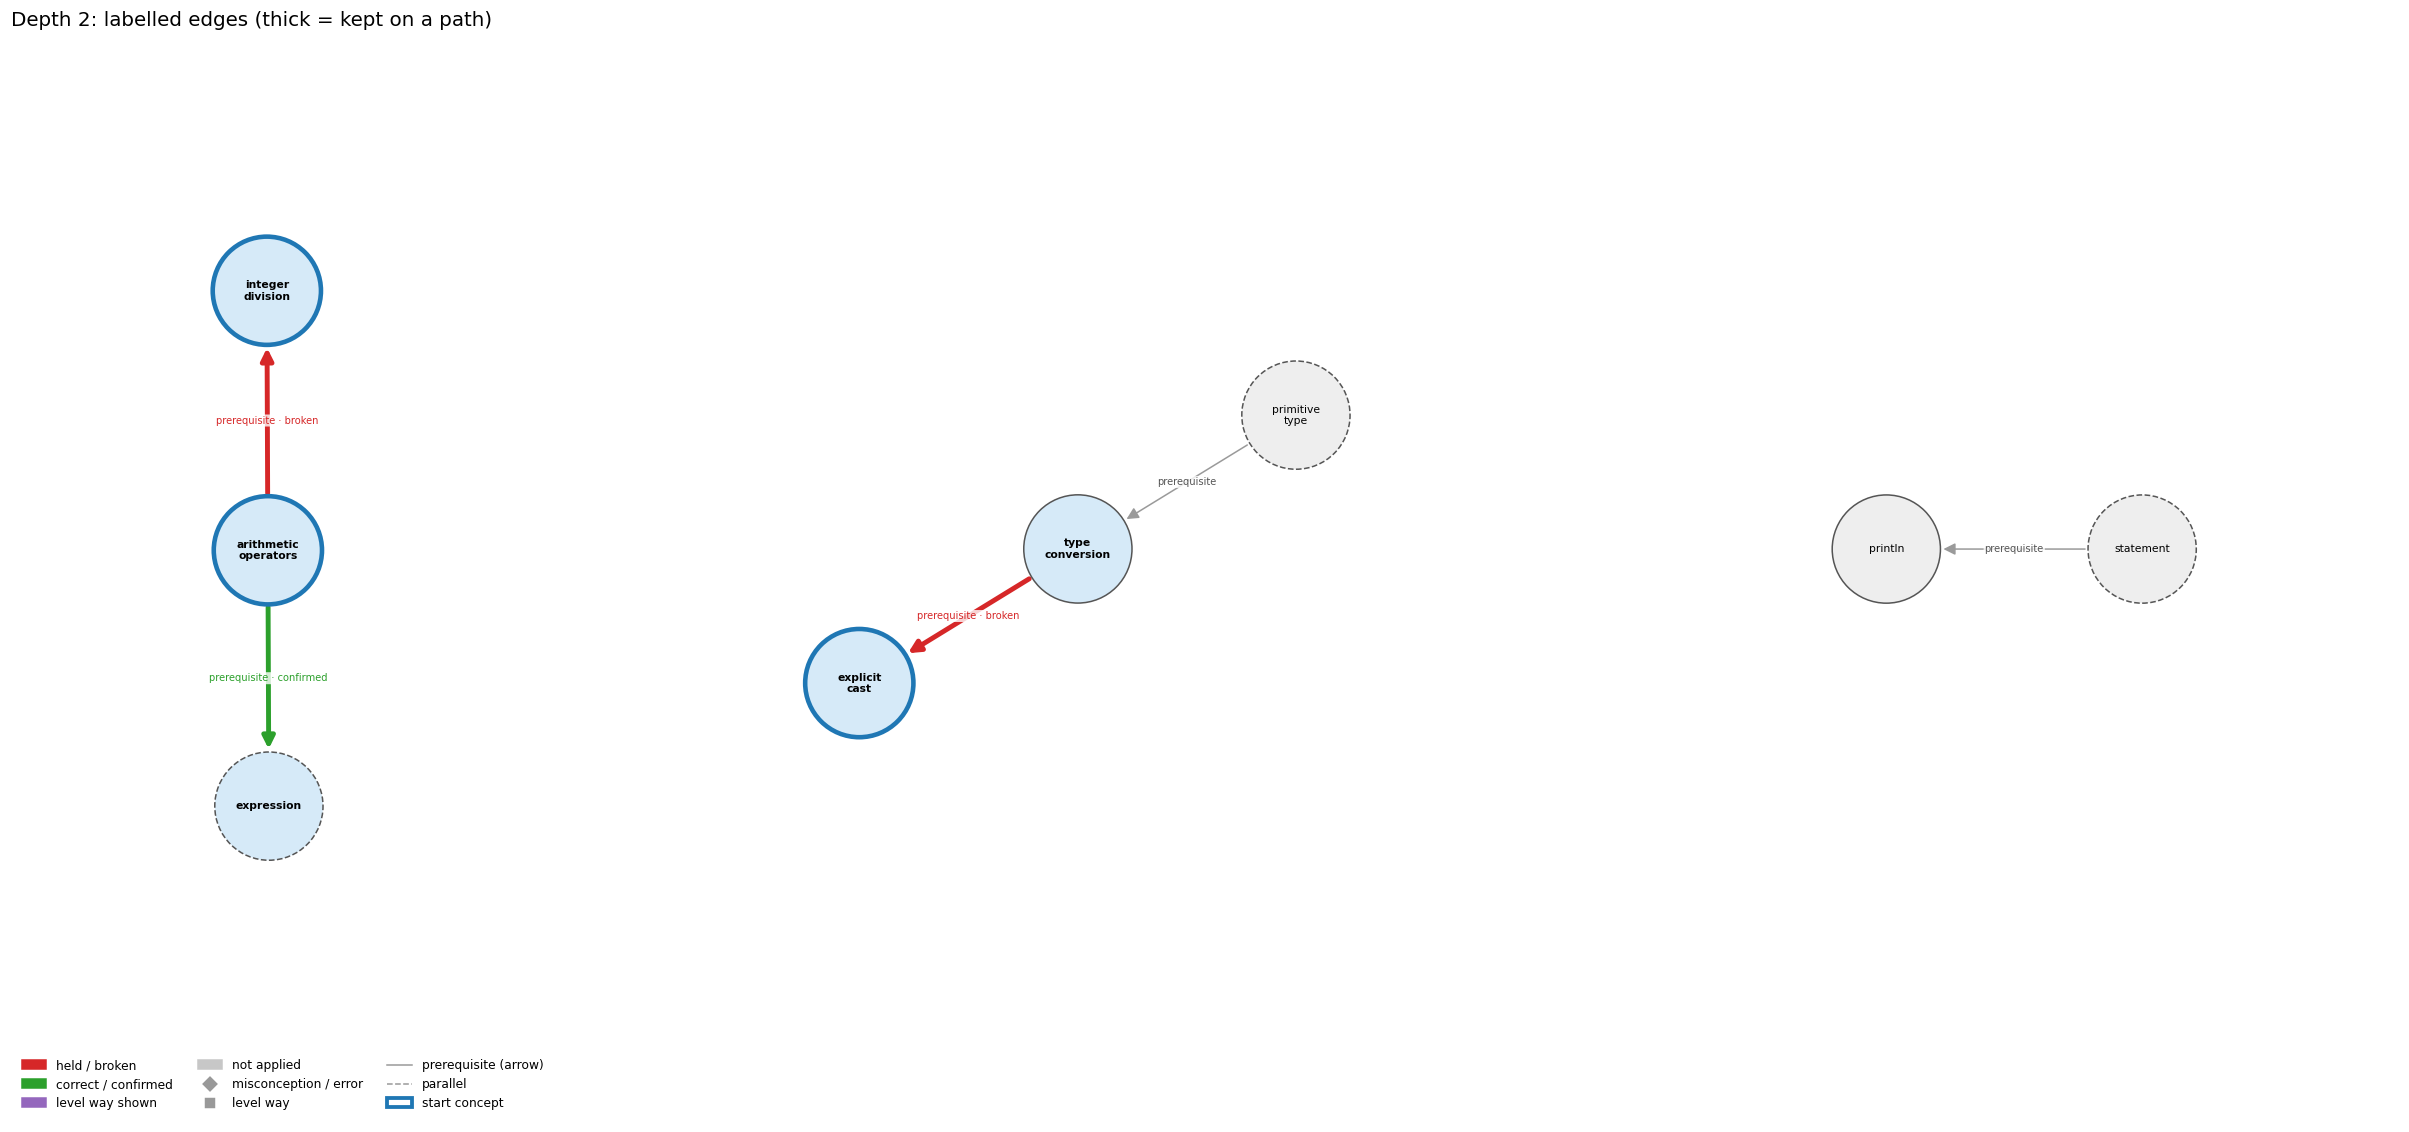

In [5]:
# Figure 5


### Depth 3: current concepts 'arithmetic_operators', 'integer_division', 'type_conversion', 'explicit_cast', 'expression'

#### type_conversion, misconceptions: 3 edges offered
Edges offered:
| edge |
|---|
| mis:type_conversion->NarrowingAssignmentAllowed \| wrong rule: A double value can be stored in an int variable like an int in a double. \| right rule: int to double is automatic; double to int needs a cast. |
| mis:type_conversion->NoCastIfSameSize \| wrong rule: If a variable is at least as big as a value, no cast is needed to assign the value. \| right rule: Assigning a double to an int needs a cast even when the value would fit, because a conversion that might involve loss of information leads to a compile-time error. |
| mis:type_conversion->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{mis:type_conversion->TargetTyping (Score: 1.0)}
```
Kept by pruning: mis:type_conversion->TargetTyping (1.00)

Label prompt for the misconception / error edges (judged together). The model saw the program, the question, the numbered clauses, and these edges with their wrong rule and right rule:
| edge |
|---|
| mis:type_conversion->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |
Model's reply:
```
mis:type_conversion->TargetTyping | held | clauses: 2, 3 | confidence: 0.8
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| mis:type_conversion->TargetTyping | held | 1.0 | 0.8 | 0.8 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |

#### type_conversion, level ways: 18 edges offered
Edges offered:
| edge |
|---|
| lvl:type_conversion@L0#0 \| level L0 way everyday_reading: Folk meaning: a number is a number, so 3, 3.0 and "3" are the same value, and a variable will take whatever form the context needs (the result 'becomes' double when stored in a double). Java rule: every value has a fixed type; conversions happen only by automatic promotion to a wider type, by an explicit cast, by conversion methods (Integer.parseInt, Math.round), or by String conversion with +. |
| lvl:type_conversion@L0#3 \| level L0 way inconsistent_trace: Points to LT (each subexpression is computed in its own type, and conversion happens only where the types meet). Applied unevenly: the student promotes before an int division on one line (treating 9/5 as 1.8) but not on another, or casts the whole expression on one pass and only the first operand on the next. (here mixing in: "If a variable is at least as big as a value, no cast is needed to assign the value") |
| lvl:type_conversion@L1#0 \| level L1 way names_the_element: Type conversion is changing a value of one type into a value of another type: automatic promotion (widening), an explicit cast, an explicit conversion method (Integer.parseInt, Double.parseDouble, Math.round), or automatic conversion to String. |
| lvl:type_conversion@L1#1 \| level L1 way states_the_rule: Java converts automatically to a type with a larger range (promotion) because no information is lost; a conversion that might lose information (double to int) requires an explicit cast or is a compile-time error; Strings and numbers convert only via methods or string conversion. |
| lvl:type_conversion@L2#0 \| level L2 way line_by_line_trace: Innermost subexpressions are evaluated in their own types first; at each binary operator the narrower operand is promoted; a cast converts the single value right after it; at an assignment the final value is converted to the variable's type (widening allowed, narrowing rejected at compile time). |
| lvl:type_conversion@L2#1 \| level L2 way output_prediction: Typical results: "1234" + 99 is the String "123499"; Integer.parseInt("123") is int 123; (int) 2.71828 is int 2; Math.round(2.71828) is long 3; 11 * 0.3 is double 3.3; 11 * (int) 0.3 is int 0; (int) (11 * 0.3) is int 3. |
| lvl:type_conversion@L2#2 \| level L2 way one_step_execution: A conversion produces a new value and never changes the source variable or its declared type: after int x = (int) pi; x is 3 and pi still holds 3.14159. |
| lvl:type_conversion@L3#0 \| level L3 way relation_to_neighbour: Conversions between primitive types follow their ranges: int to double happens automatically, double to int needs a cast that drops the fraction, and boolean converts to no numeric type. |
| lvl:type_conversion@L3#1 \| level L3 way relation_to_neighbour: Parsing methods are explicit type conversion from String to a number: a method takes an argument of one type and produces a result of another. |
| lvl:type_conversion@L3#2 \| level L3 way relation_to_neighbour: A cast is the explicit conversion between primitive types, required when information may be lost: (int) 2.71828 is 2. |
| lvl:type_conversion@L3#3 \| level L3 way relation_to_neighbour: Widening (promotion) is the automatic kind of conversion, applied at operators and assignments when the target type has a larger range. |
| lvl:type_conversion@L3#4 \| level L3 way purpose_of_the_whole: Adapts data between parts of a program: command-line text to numbers, int counts to double for an average ((double) sum / n), doubles to int indices or counts. |
| lvl:type_conversion@L4#0 \| level L4 way predict_a_change: Moving the point of conversion changes the result: (double) (a / b) differs from (double) a / b, and (int) 11 * 0.3 differs from (int) (11 * 0.3). Widening int to double and back is reversible for int values; narrowing double to int loses the fraction irreversibly. |
| lvl:type_conversion@L4#1 \| level L4 way transfer_to_a_new_program: Rely on automatic promotion when mixing int with double; write a cast only when you intend to drop information; use parse methods for text input and string conversion for output; paying attention to types avoids subtle bugs. |
| lvl:type_conversion@L4#2 \| level L4 way diagnose_an_error: rule broken: A conversion that may lose information needs an explicit cast. Kind: compile-time. Trigger class: Assigning or passing a double (or long) expression to an int, e.g. int n = 11 * 0.3; (possible loss of precision). |
| lvl:type_conversion@L4#3 \| level L4 way diagnose_an_error: rule broken: Promotion happens per operator, after an int division has already truncated. Kind: silent logic error. Trigger class: All-int division inside a double formula, e.g. double y = 1 / 3; or (9/5) * c + 32. |
| lvl:type_conversion@L4#4 \| level L4 way diagnose_an_error: rule broken: Casts work only between compatible types; a String is converted with a parse method. Kind: compile-time. Trigger class: (int) str with a String str, or (int) flag with a boolean. |
| lvl:type_conversion@L4#5 \| level L4 way diagnose_an_error: rule broken: A parse method accepts only a valid textual representation of the number. Kind: run-time exception. Trigger class: Integer.parseInt of text that is not an integer in digits ("five", "12.2", ""). |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{lvl:type_conversion@L2#0 (Score: 0.45)}
{lvl:type_conversion@L4#3 (Score: 0.3)}
{lvl:type_conversion@L4#0 (Score: 0.25)}
```
Kept by pruning: lvl:type_conversion@L2#0 (0.45), lvl:type_conversion@L4#3 (0.30), lvl:type_conversion@L4#0 (0.25)

Label prompt for level way lvl:type_conversion@L2#0 (the model saw only the concept, the way's name 'line by line trace' and its text; no level):
> Innermost subexpressions are evaluated in their own types first; at each binary operator the narrower operand is promoted; a cast converts the single value right after it; at an assignment the final value is converted to the variable's type (widening allowed, narrowing rejected at compile time).

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.93
```

Label prompt for level way lvl:type_conversion@L4#3 (the model saw only the concept, the way's name 'diagnose an error' and its text; no level):
> rule broken: Promotion happens per operator, after an int division has already truncated. Kind: silent logic error. Trigger class: All-int division inside a double formula, e.g. double y = 1 / 3; or (9/5) * c + 32.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.97
```

Label prompt for level way lvl:type_conversion@L4#0 (the model saw only the concept, the way's name 'predict a change' and its text; no level):
> Moving the point of conversion changes the result: (double) (a / b) differs from (double) a / b, and (int) 11 * 0.3 differs from (int) (11 * 0.3). Widening int to double and back is reversible for int values; narrowing double to int loses the fraction irreversibly.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.95
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| lvl:type_conversion@L2#0 | not applied |  |  | 0.0 |  |  |
| lvl:type_conversion@L4#3 | not applied |  |  | 0.0 |  |  |
| lvl:type_conversion@L4#0 | not applied |  |  | 0.0 |  |  |

#### expression, misconceptions: 8 edges offered
Edges offered:
| edge |
|---|
| err:expression->ExpressionOnLeftOfAssignment \| wrong rule: Writes a + b = c; or 7 = a; as if = were a math equation. \| right rule: The left side of an assignment must be a single variable; only the right side can be an expression. |
| mis:expression->AssignmentIsEquation \| wrong rule: An assignment states a lasting equality between its two sides, so y = x - y can be solved like the equation x = 2y and x = x + 5 relates two equal quantities. \| right rule: An assignment is a one-time action: evaluate the right side with current values, then store the result in the left variable. |
| mis:expression->AssignmentNotExpression \| wrong rule: An assignment cannot be used inside a larger expression, so a condition like (x = read()) != v is not allowed. \| right rule: An assignment is an expression whose value is the value assigned, so (x = v) both stores v in x and gives v. |
| mis:expression->NoAtomicExpression \| wrong rule: A single variable x or a literal on its own is not an expression. \| right rule: A single variable or literal is an expression whose value is just that value. |
| mis:expression->OutsideInMethodNesting \| wrong rule: In f(g(x)), f runs first and then g runs. \| right rule: In f(g(x)), g(x) is evaluated first and its result is passed to f. |
| mis:expression->ParenthesesOnlyIfArgument \| wrong rule: () are optional on a no-argument call like println \| right rule: A method call always needs parentheses, so an empty line is printed with System.out.println();. |
| mis:expression->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |
| mis:expression->VariablesHoldExpressions \| wrong rule: = stores the expression itself, not its computed value \| right rule: y = x + k; stores the value that x + k has at that moment, so later changes to x do not change y. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
mis:expression->TargetTyping (0.80), mis:expression->VariablesHoldExpressions (0.10), mis:expression->AssignmentIsEquation (0.10)
```
Kept by pruning: mis:expression->TargetTyping (0.80), mis:expression->VariablesHoldExpressions (0.10), mis:expression->AssignmentIsEquation (0.10)

Label prompt for the misconception / error edges (judged together). The model saw the program, the question, the numbered clauses, and these edges with their wrong rule and right rule:
| edge |
|---|
| mis:expression->TargetTyping \| wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. \| right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |
| mis:expression->VariablesHoldExpressions \| wrong rule: = stores the expression itself, not its computed value \| right rule: y = x + k; stores the value that x + k has at that moment, so later changes to x do not change y. |
| mis:expression->AssignmentIsEquation \| wrong rule: An assignment states a lasting equality between its two sides, so y = x - y can be solved like the equation x = 2y and x = x + 5 relates two equal quantities. \| right rule: An assignment is a one-time action: evaluate the right side with current values, then store the result in the left variable. |
Model's reply:
```
mis:expression->TargetTyping | held | clauses: 2, 3 | confidence: 0.85
mis:expression->VariablesHoldExpressions | correct | clauses: 3 | confidence: 0.6
mis:expression->AssignmentIsEquation | not applied | clauses: none | confidence: 0.7
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| mis:expression->TargetTyping | held | 0.8 | 0.85 | 0.68 | c2, c3 | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| mis:expression->VariablesHoldExpressions | correct | 0.1 | 0.6 | 0.06 | c3 | so 7 / 2 gives 3.5 and that is stored in avg |
| mis:expression->AssignmentIsEquation | not applied |  |  | 0.0 |  |  |

#### expression, level ways: 19 edges offered
Edges offered:
| edge |
|---|
| lvl:expression@L0#0 \| level L0 way everyday_reading: In maths an expression such as 7/2 or x + y names an exact number, and 'expression' means a formula with operators. In Java, any code that evaluates to a typed value is an expression, including a lone literal or variable, and with ints 7/2 evaluates to 3. |
| lvl:expression@L0#2 \| level L0 way inconsistent_trace: Points to LT (replace each variable with its current value, then apply operators in precedence order). Applied unevenly, a student substitutes current values for some variables and old or future values for others, or respects precedence in one subexpression only. (here mixing in: "a single literal or variable "isn't an expression"") |
| lvl:expression@L1#0 \| level L1 way names_the_element: Expression: a literal, a variable, or a sequence of operations (operators, method calls) on them that produces one value. |
| lvl:expression@L1#1 \| level L1 way states_the_rule: Each operand of an operator can itself be any expression, and a parenthesized expression has the same value as the expression inside. Every expression has a type, determined by its operators and operands. |
| lvl:expression@L2#0 \| level L2 way line_by_line_trace: Operands are evaluated left to right, each fully before its operator is applied. Precedence and parentheses decide the grouping, and a method's arguments are all evaluated before the method is called. |
| lvl:expression@L2#1 \| level L2 way output_prediction: An expression produces one value of a type fixed by its operands: hour * 60 + minute with hour = 11 and minute = 59 is the int 719. |
| lvl:expression@L2#2 \| level L2 way one_step_execution: Evaluating an expression changes no variable unless it contains an assignment, ++/-- or a method with side effects. The value goes to the enclosing statement, and an expression statement discards it. |
| lvl:expression@L3#0 \| level L3 way relation_to_neighbour: A variable name inside an expression contributes the variable's value at the moment of evaluation. |
| lvl:expression@L3#1 \| level L3 way relation_to_neighbour: Operators combine operand values into a new value, and the operand types choose the operation (int / truncates, double / does not). |
| lvl:expression@L3#2 \| level L3 way relation_to_neighbour: With several operators, precedence and left associativity decide the grouping, and parentheses override both. |
| lvl:expression@L3#3 \| level L3 way relation_to_neighbour: A comparison takes numeric expressions and yields a boolean expression, and it has lower precedence than arithmetic, so a + b < c compares the sum. |
| lvl:expression@L3#4 \| level L3 way relation_to_neighbour: A method call is an expression usable wherever a value of its return type is, and its arguments are expressions evaluated before the call. |
| lvl:expression@L3#5 \| level L3 way purpose_of_the_whole: Expressions compute new values from existing ones. They form the right side of every assignment, every condition, every method argument and every printed value. |
| lvl:expression@L4#0 \| level L4 way predict_a_change: Adding parentheses that match the default grouping keeps the value, and rewriting with an equivalent formula (4 * (x - 3) as 4*x - 12) keeps it for ints. Changing one operand's type (3 to 3.0) can change both the result's type and its value. |
| lvl:expression@L4#1 \| level L4 way transfer_to_a_new_program: Use an expression wherever a value is needed. Split a long or unclear expression into named intermediate variables, and add parentheses wherever the grouping is not obvious. |
| lvl:expression@L4#2 \| level L4 way diagnose_an_error: rule broken: The left-hand side of = must be a single variable; only the right-hand side may be an arbitrary expression. Kind: compile-time. Trigger class: Any assignment whose left side is a literal or compound expression (7 = a; a + b = c;): 'unexpected type, required: variable'. |
| lvl:expression@L4#3 \| level L4 way diagnose_an_error: rule broken: Only assignments, increments, method calls and object creation can stand alone as statements. Kind: compile-time. Trigger class: A bare expression line such as x + 1; or a == b;: 'not a statement'. |
| lvl:expression@L4#4 \| level L4 way diagnose_an_error: rule broken: Operators accept only operands of suitable types. Kind: compile-time. Trigger class: Applying arithmetic to Strings ("Hello" - 1) or comparing booleans with <: 'bad operand types'. |
| lvl:expression@L4#5 \| level L4 way diagnose_an_error: rule broken: An int division or remainder by zero cannot be evaluated. Kind: run-time exception. Trigger class: Any int / or % whose right operand evaluates to 0: ArithmeticException. |

Prune: the model's reply (edge id and score; the kept edges sum to 1):
```
{lvl:expression@L0#0 (Score: 0.5)}
{lvl:expression@L3#1 (Score: 0.3)}
{lvl:expression@L3#2 (Score: 0.2)}
```
Kept by pruning: lvl:expression@L0#0 (0.50), lvl:expression@L3#1 (0.30), lvl:expression@L3#2 (0.20)

Label prompt for level way lvl:expression@L0#0 (the model saw only the concept, the way's name 'everyday reading' and its text; no level):
> In maths an expression such as 7/2 or x + y names an exact number, and 'expression' means a formula with operators. In Java, any code that evaluates to a typed value is an expression, including a lone literal or variable, and with ints 7/2 evaluates to 3.

Model's reply:
```
Label: shown
Clauses: 1, 3
Confidence: 0.8
```

Label prompt for level way lvl:expression@L3#1 (the model saw only the concept, the way's name 'relation to neighbour' and its text; no level):
> Operators combine operand values into a new value, and the operand types choose the operation (int / truncates, double / does not).

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.85
```

Label prompt for level way lvl:expression@L3#2 (the model saw only the concept, the way's name 'relation to neighbour' and its text; no level):
> With several operators, precedence and left associativity decide the grouping, and parentheses override both.

Model's reply:
```
Label: not shown
Clauses: none
Confidence: 0.9
```

Parsed labels:
| edge | label | prune score | confidence | score | clauses | words |
|---|---|---|---|---|---|---|
| lvl:expression@L0#0 | shown | 0.5 | 0.8 | 0.4 | c1, c3 | It prints 3.5; so 7 / 2 gives 3.5 and that is stored in avg |
| lvl:expression@L3#1 | not applied |  |  | 0.0 |  |  |
| lvl:expression@L3#2 | not applied |  |  | 0.0 |  |  |

**Kept on a path at this depth** (best N in tiers: held misconception / broken edge, then held error, then correct / confirmed / shown):

mis:type_conversion->TargetTyping [held, tier 0, 0.80], mis:expression->TargetTyping [held, tier 0, 0.68], lvl:expression@L0#0 [shown, tier 2, 0.40]

**Clause coverage after this depth:**
| clause | text | covered by |
|---|---|---|
| c1 | It prints 3.5 | mis:explicit_cast->CastAfterIntDivision |
| c2 | The (double) cast turns the division into a decimal division | mis:explicit_cast->CastAfterIntDivision |
| c3 | so 7 / 2 gives 3.5 and that is stored in avg | mis:explicit_cast->CastAfterIntDivision |

**Graph check, not yet read (the walk may not stop while these remain):** pre:primitive_type->type_conversion


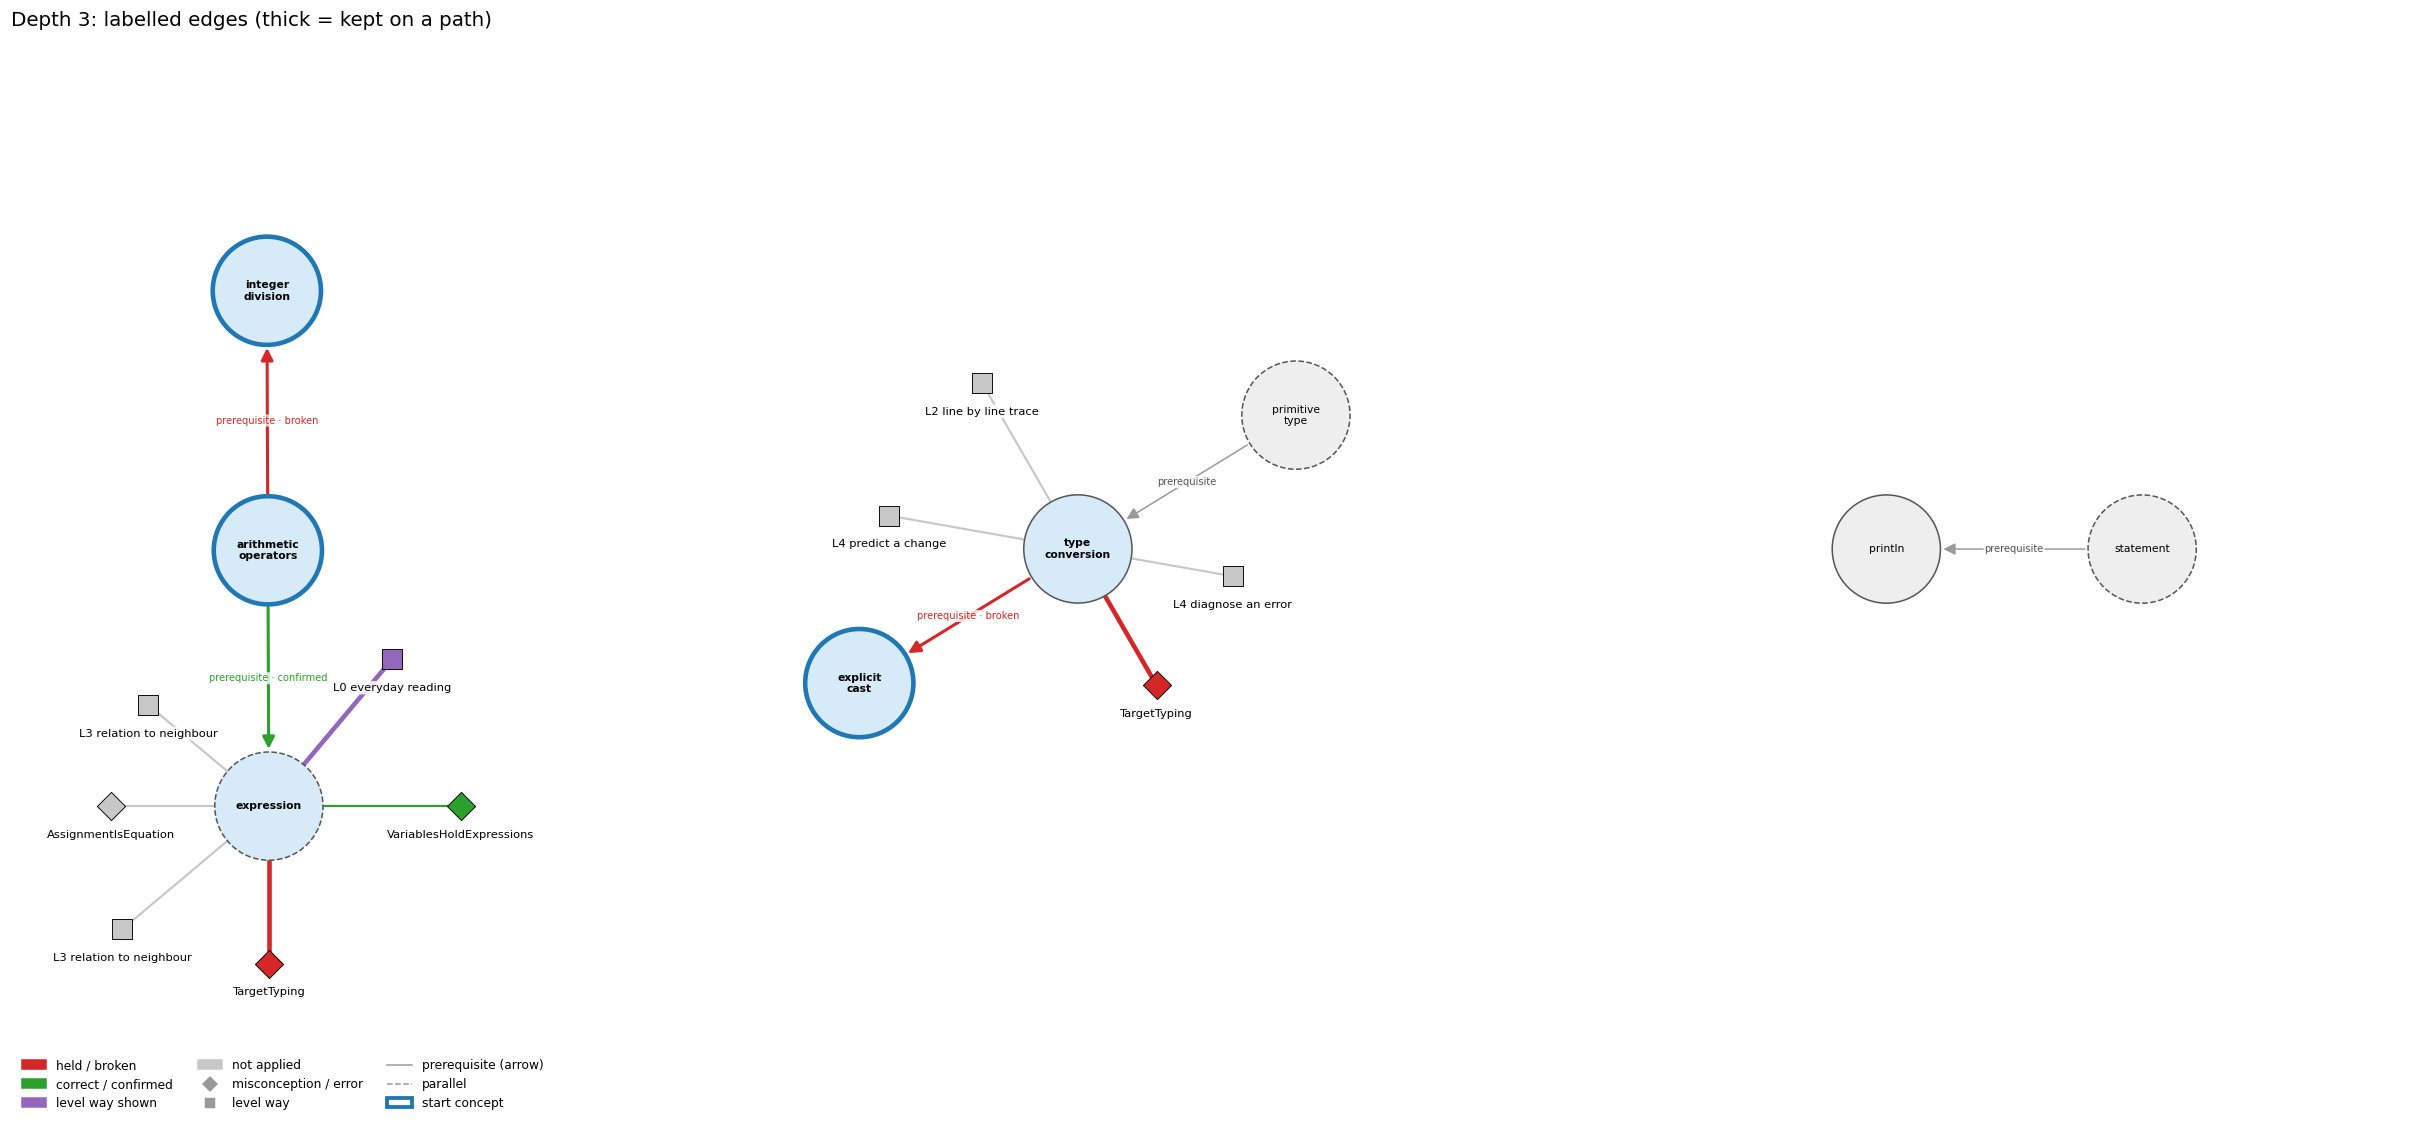

In [6]:
# Figure 6


## 4. Diagnosis (rules over the labelled graph, no model)
Root-cause walk: held on ['explicit_cast', 'expression', 'integer_division', 'type_conversion'], broken at [] (consequences: pre:arithmetic_operators->integer_division, pre:type_conversion->explicit_cast), prerequisites {'expression': ['arithmetic_operators'], 'integer_division': ['arithmetic_operators'], 'type_conversion': ['primitive_type'], 'println': ['statement'], 'explicit_cast': ['type_conversion']}
- explicit_cast: L0 via misconception "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
- expression: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
- integer_division: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
- type_conversion: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"

**Stop:** max depth at depth 3; prompts {'prune': 13, 'label': 22}, fresh model calls 0, cache hits 35

### Held misconceptions
| concept | misconception | kind | quote | score | shares_evidence_with |
|---|---|---|---|---|---|
| type_conversion | TargetTyping | misconception | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.8 |  |
| explicit_cast | CastAfterIntDivision | misconception | It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.76 |  |
| expression | TargetTyping | misconception | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.68 |  |
| integer_division | CastAfterIntDivision | misconception | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.665 |  |

### Broken concept edges
| edge | quote | score | consequence_of |
|---|---|---|---|
| pre:arithmetic_operators->integer_division | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.95 | mis:explicit_cast->CastAfterIntDivision |
| pre:type_conversion->explicit_cast | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | 0.8 | mis:explicit_cast->CastAfterIntDivision |

### Root cause: type_conversion / TargetTyping

### Level per concept
| concept | level | way | misconception | source | quote | rule | also | note |
|---|---|---|---|---|---|---|---|---|
| explicit_cast | L0 | misconception | CastAfterIntDivision | level_mis_links | It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | wrong rule: (double) (3 / 5) is 0.6. Right rule: The integer division 3 / 5 = 0 happens inside the parentheses before the cast, so the result is 0.0; write (double) 3 / 5 to get 0.6. |  |  |
| expression | L0 | misconception | TargetTyping | level_mis_links | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. Right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints. |  |  |
| integer_division | L0 | misconception | CastAfterIntDivision | level_mis_links | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | wrong rule: (double) (3 / 5) is 0.6. Right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0. |  |  |
| type_conversion | L0 | misconception | TargetTyping | level_mis_links | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg | wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. Right rule: The type of a numerical expression is determined by its operands, so double d = a / b; with int a and b still divides as ints and only then widens the result (1 / 3 gives 0.0). |  |  |

### Overall level: L0

Clause coverage (final):
| clause | covered by |
|---|---|
| It prints 3.5 | mis:explicit_cast->CastAfterIntDivision |
| The (double) cast turns the division into a decimal division | mis:explicit_cast->CastAfterIntDivision |
| so 7 / 2 gives 3.5 and that is stored in avg | mis:explicit_cast->CastAfterIntDivision |


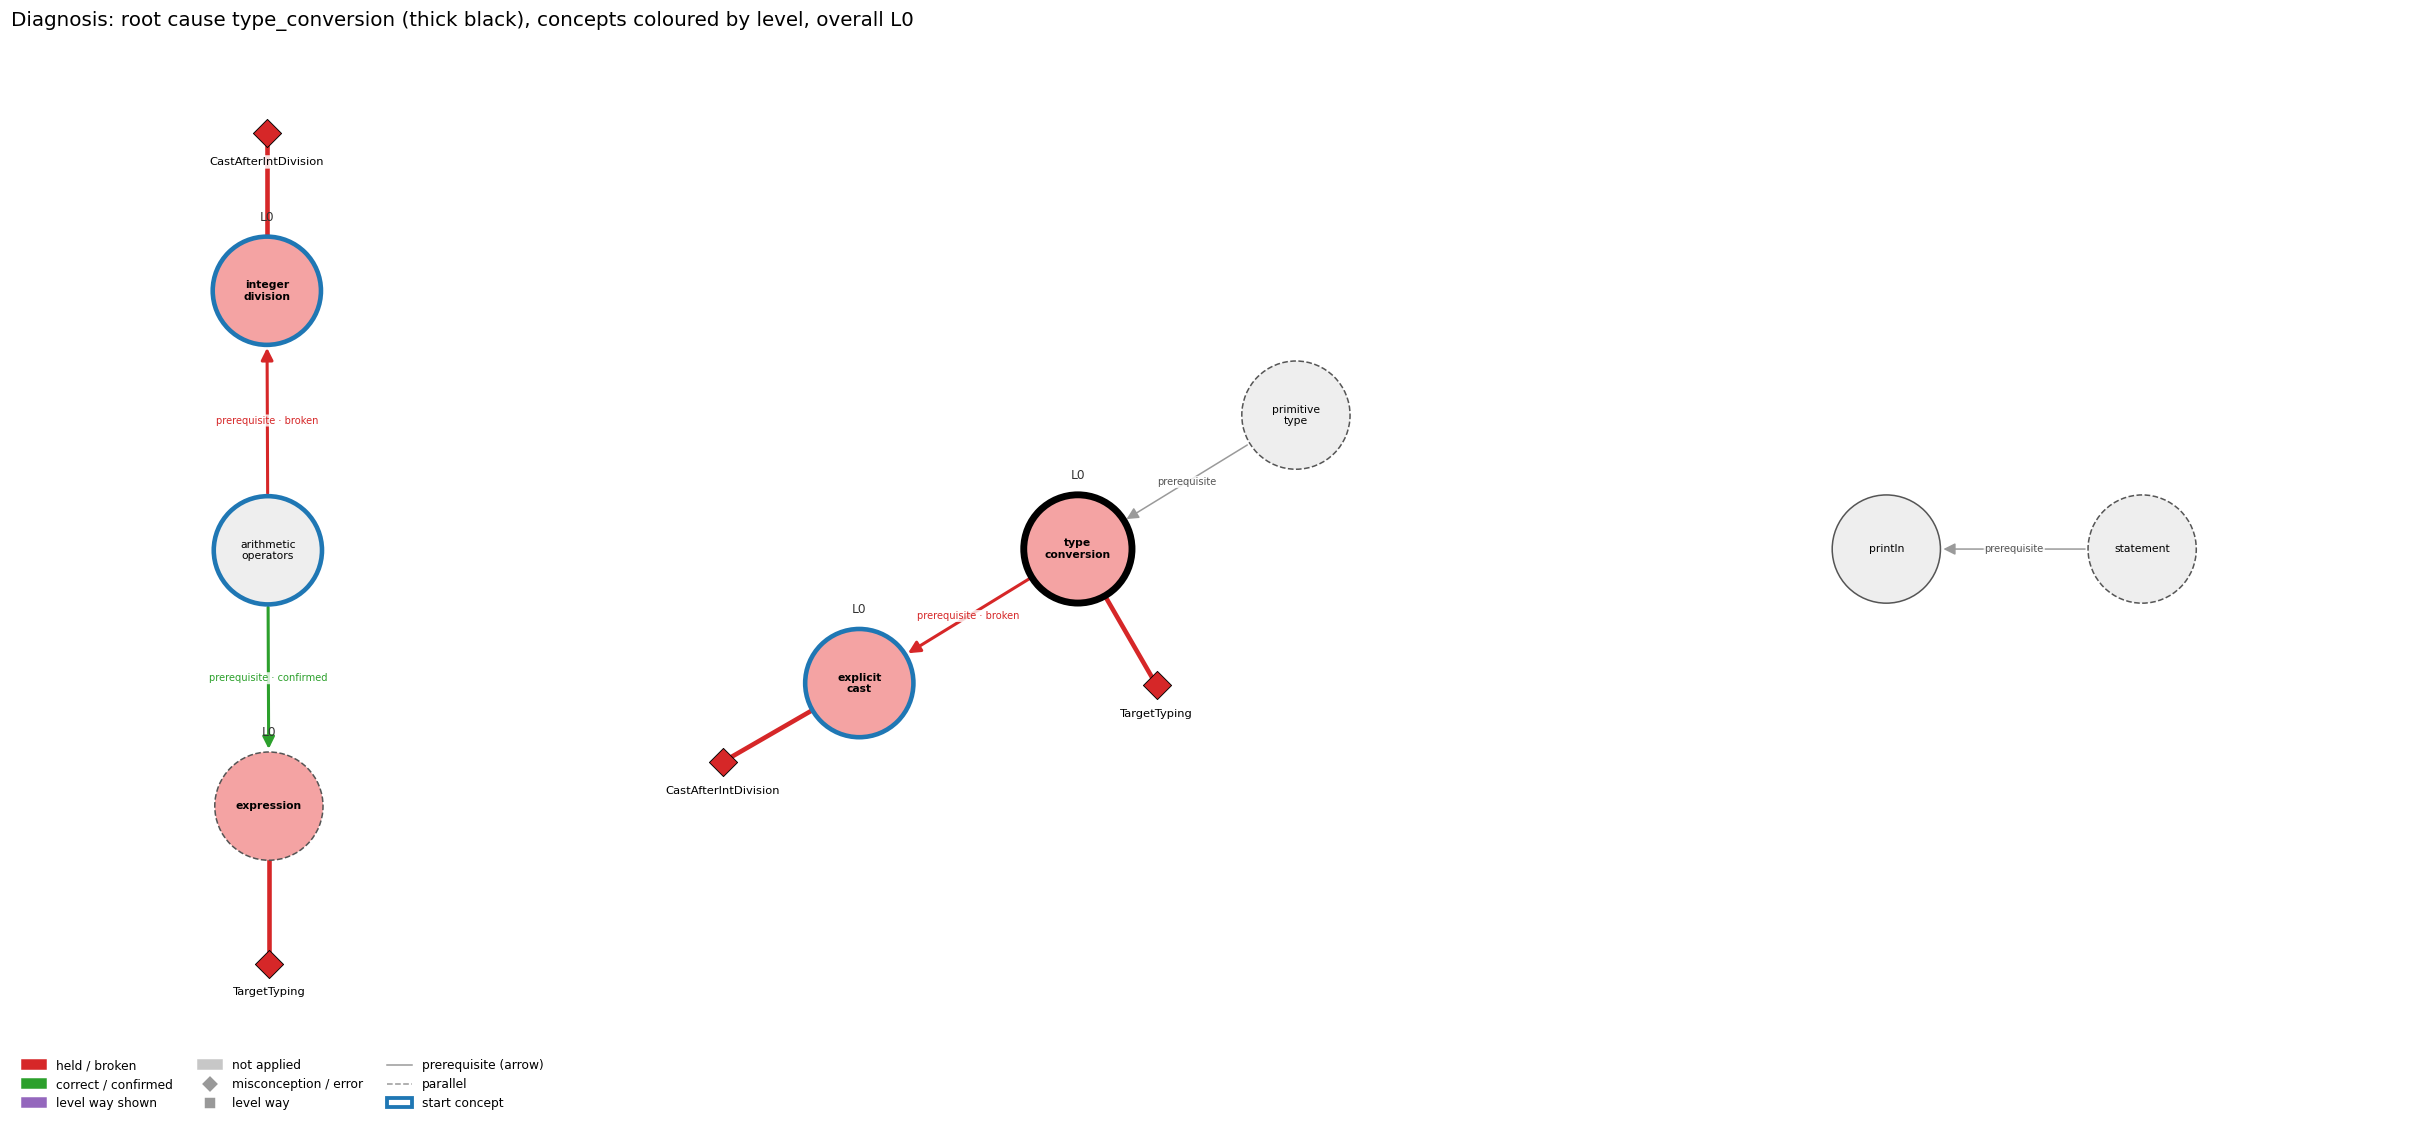

In [7]:
# Figure 7 (final picture)


## 5. Every labelled edge (the evidence list, kept or not)
| depth | source | edge | kind | label | prune_score | confidence | score | clauses | quote |
|---|---|---|---|---|---|---|---|---|---|
| 1 | explicit_cast | mis:explicit_cast->CastAfterIntDivision | misconception | held | 0.8 | 0.95 | 0.76 | [1, 2, 3] | It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 1 | integer_division | mis:integer_division->CastAfterIntDivision | misconception | held | 0.7000000000000001 | 0.95 | 0.665 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 1 | integer_division | lvl:integer_division@L0#4 | level | shown | 0.5 | 0.85 | 0.425 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 2 | explicit_cast | pre:type_conversion->explicit_cast | prerequisite | broken | 1.0 | 0.8 | 0.8 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 2 | integer_division | pre:arithmetic_operators->integer_division | prerequisite | broken | 1.0 | 0.95 | 0.95 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 2 | arithmetic_operators | pre:arithmetic_operators->expression | prerequisite | confirmed | 1.0 | 0.6 | 0.6 | [3] | so 7 / 2 gives 3.5 and that is stored in avg |
| 3 | type_conversion | mis:type_conversion->TargetTyping | misconception | held | 1.0 | 0.8 | 0.8 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 3 | expression | mis:expression->TargetTyping | misconception | held | 0.8 | 0.85 | 0.68 | [2, 3] | The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg |
| 3 | expression | mis:expression->VariablesHoldExpressions | misconception | correct | 0.1 | 0.6 | 0.06 | [3] | so 7 / 2 gives 3.5 and that is stored in avg |
| 3 | expression | lvl:expression@L0#0 | level | shown | 0.5 | 0.8 | 0.4 | [1, 3] | It prints 3.5; so 7 / 2 gives 3.5 and that is stored in avg |

## 6. The paths (what the keep step kept, depth by depth)
| depth | source | edge | kind | label | score | clauses |
|---|---|---|---|---|---|---|
| 1 | explicit_cast | mis:explicit_cast->CastAfterIntDivision | misconception | held | 0.76 | [1, 2, 3] |
| 1 | integer_division | mis:integer_division->CastAfterIntDivision | misconception | held | 0.665 | [2, 3] |
| 1 | integer_division | lvl:integer_division@L0#4 | level | shown | 0.425 | [2, 3] |
| 2 | integer_division | pre:arithmetic_operators->integer_division | prerequisite | broken | 0.95 | [2, 3] |
| 2 | explicit_cast | pre:type_conversion->explicit_cast | prerequisite | broken | 0.8 | [2, 3] |
| 2 | arithmetic_operators | pre:arithmetic_operators->expression | prerequisite | confirmed | 0.6 | [3] |
| 3 | type_conversion | mis:type_conversion->TargetTyping | misconception | held | 0.8 | [2, 3] |
| 3 | expression | mis:expression->TargetTyping | misconception | held | 0.68 | [2, 3] |
| 3 | expression | lvl:expression@L0#0 | level | shown | 0.4 | [1, 3] |

## 7. Raw traversal log
```
clauses: It prints 3.5 | The (double) cast turns the division into a decimal division | so 7 / 2 gives 3.5 and that is stored in avg
start: BM25 of the answer against each tagged concept: explicit_cast 15.54 (hits 1), integer_division 12.63 (hits 1), arithmetic_operators 7.88 (hits 1), println 7.20 (hits 1), type_conversion 7.08 (hits 1)
start: chosen explicit_cast, integer_division, arithmetic_operators
start concepts (3): explicit_cast, integer_division, arithmetic_operators
--- depth 1: current concepts ['explicit_cast', 'integer_division', 'arithmetic_operators']
  explicit_cast (misconceptions): 6 candidates -> kept mis:explicit_cast->CastAfterIntDivision (0.80), mis:explicit_cast->CastAppliesToWholeExpression (0.12), mis:explicit_cast->LaterDoubleLiteralFixesDivision (0.08)
    mis:explicit_cast->CastAfterIntDivision -> held (0.76) "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
    mis:explicit_cast->CastAppliesToWholeExpression -> not applied (0.00) ""
    mis:explicit_cast->LaterDoubleLiteralFixesDivision -> not applied (0.00) ""
  explicit_cast (level ways): 19 candidates -> kept lvl:explicit_cast@L2#1 (0.45), lvl:explicit_cast@L2#0 (0.35), lvl:explicit_cast@L4#1 (0.20)
    lvl:explicit_cast@L2#1 -> not applied (0.00) ""
    lvl:explicit_cast@L2#0 -> not applied (0.00) ""
    lvl:explicit_cast@L4#1 -> not applied (0.00) ""
  integer_division (misconceptions): 6 candidates -> kept mis:integer_division->CastAfterIntDivision (0.70), mis:integer_division->IntegerDivisionGivesFraction (0.20), mis:integer_division->TargetTyping (0.10)
    mis:integer_division->CastAfterIntDivision -> held (0.67) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
    mis:integer_division->IntegerDivisionGivesFraction -> not applied (0.00) ""
    mis:integer_division->TargetTyping -> not applied (0.00) ""
  integer_division (level ways): 16 candidates -> kept lvl:integer_division@L0#4 (0.50), lvl:integer_division@L2#0 (0.30), lvl:integer_division@L0#0 (0.20)
    lvl:integer_division@L0#4 -> shown (0.42) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
    lvl:integer_division@L2#0 -> not applied (0.00) ""
    lvl:integer_division@L0#0 -> not applied (0.00) ""
  arithmetic_operators (misconceptions): 3 candidates -> kept 
  arithmetic_operators (level ways): 18 candidates -> kept lvl:arithmetic_operators@L2#1 (0.50), lvl:arithmetic_operators@L4#0 (0.30), lvl:arithmetic_operators@L2#0 (0.20)
    lvl:arithmetic_operators@L2#1 -> not applied (0.00) ""
    lvl:arithmetic_operators@L4#0 -> not applied (0.00) ""
    lvl:arithmetic_operators@L2#0 -> not applied (0.00) ""
  kept: mis:explicit_cast->CastAfterIntDivision [held, tier 0, 0.76], mis:integer_division->CastAfterIntDivision [held, tier 0, 0.67], lvl:integer_division@L0#4 [shown, tier 2, 0.42]
  clause coverage: c1 <- mis:explicit_cast->CastAfterIntDivision; c2 <- mis:explicit_cast->CastAfterIntDivision; c3 <- mis:explicit_cast->CastAfterIntDivision
  not yet read: pre:arithmetic_operators->expression, pre:arithmetic_operators->integer_division, pre:type_conversion->explicit_cast
--- depth 2: current concepts ['explicit_cast', 'integer_division', 'arithmetic_operators']
  explicit_cast (concept edges): 1 candidates -> kept pre:type_conversion->explicit_cast (1.00)
    pre:type_conversion->explicit_cast -> broken (0.80) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  integer_division (concept edges): 1 candidates -> kept pre:arithmetic_operators->integer_division (1.00)
    pre:arithmetic_operators->integer_division -> broken (0.95) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  arithmetic_operators (concept edges): 1 candidates -> kept pre:arithmetic_operators->expression (1.00)
    pre:arithmetic_operators->expression -> confirmed (0.60) "so 7 / 2 gives 3.5 and that is stored in avg"
  kept: pre:arithmetic_operators->integer_division [broken, tier 0, 0.95], pre:type_conversion->explicit_cast [broken, tier 0, 0.80], pre:arithmetic_operators->expression [confirmed, tier 2, 0.60]
  reached across pre:type_conversion->explicit_cast, entered next: type_conversion
  reached across pre:arithmetic_operators->expression, entered next: expression
  clause coverage: c1 <- mis:explicit_cast->CastAfterIntDivision; c2 <- mis:explicit_cast->CastAfterIntDivision; c3 <- mis:explicit_cast->CastAfterIntDivision
  not yet read: own edges of expression, own edges of type_conversion
--- depth 3: current concepts ['arithmetic_operators', 'integer_division', 'type_conversion', 'explicit_cast', 'expression']
  type_conversion (misconceptions): 3 candidates -> kept mis:type_conversion->TargetTyping (1.00)
    mis:type_conversion->TargetTyping -> held (0.80) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  type_conversion (level ways): 18 candidates -> kept lvl:type_conversion@L2#0 (0.45), lvl:type_conversion@L4#3 (0.30), lvl:type_conversion@L4#0 (0.25)
    lvl:type_conversion@L2#0 -> not applied (0.00) ""
    lvl:type_conversion@L4#3 -> not applied (0.00) ""
    lvl:type_conversion@L4#0 -> not applied (0.00) ""
  expression (misconceptions): 8 candidates -> kept mis:expression->TargetTyping (0.80), mis:expression->VariablesHoldExpressions (0.10), mis:expression->AssignmentIsEquation (0.10)
    mis:expression->TargetTyping -> held (0.68) "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
    mis:expression->VariablesHoldExpressions -> correct (0.06) "so 7 / 2 gives 3.5 and that is stored in avg"
    mis:expression->AssignmentIsEquation -> not applied (0.00) ""
  expression (level ways): 19 candidates -> kept lvl:expression@L0#0 (0.50), lvl:expression@L3#1 (0.30), lvl:expression@L3#2 (0.20)
    lvl:expression@L0#0 -> shown (0.40) "It prints 3.5; so 7 / 2 gives 3.5 and that is stored in avg"
    lvl:expression@L3#1 -> not applied (0.00) ""
    lvl:expression@L3#2 -> not applied (0.00) ""
  kept: mis:type_conversion->TargetTyping [held, tier 0, 0.80], mis:expression->TargetTyping [held, tier 0, 0.68], lvl:expression@L0#0 [shown, tier 2, 0.40]
  clause coverage: c1 <- mis:explicit_cast->CastAfterIntDivision; c2 <- mis:explicit_cast->CastAfterIntDivision; c3 <- mis:explicit_cast->CastAfterIntDivision
  not yet read: pre:primitive_type->type_conversion
  root-cause walk: held on ['explicit_cast', 'expression', 'integer_division', 'type_conversion'], broken at [] (consequences: pre:arithmetic_operators->integer_division, pre:type_conversion->explicit_cast), prerequisites {'expression': ['arithmetic_operators'], 'integer_division': ['arithmetic_operators'], 'type_conversion': ['primitive_type'], 'println': ['statement'], 'explicit_cast': ['type_conversion']}
  level explicit_cast: L0 via misconception "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  level expression: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  level integer_division: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
  level type_conversion: L0 via misconception "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg"
```

## 8. Full diagnosis JSON
```json
{
 "scenario": "MY01",
 "settings": {
  "width": 3,
  "depth": 3,
  "prune_tools": "llm",
  "model": "claude-opus-5-5",
  "backend": "claude-cli"
 },
 "clauses": [
  "It prints 3.5",
  "The (double) cast turns the division into a decimal division",
  "so 7 / 2 gives 3.5 and that is stored in avg"
 ],
 "start_concepts": [
  "explicit_cast",
  "integer_division",
  "arithmetic_operators"
 ],
 "held_misconceptions": [
  {
   "concept": "type_conversion",
   "misconception": "TargetTyping",
   "kind": "misconception",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.8
  },
  {
   "concept": "explicit_cast",
   "misconception": "CastAfterIntDivision",
   "kind": "misconception",
   "quote": "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.76
  },
  {
   "concept": "expression",
   "misconception": "TargetTyping",
   "kind": "misconception",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.68
  },
  {
   "concept": "integer_division",
   "misconception": "CastAfterIntDivision",
   "kind": "misconception",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.665
  }
 ],
 "error_evidence": [],
 "broken_edges": [
  {
   "edge": "pre:arithmetic_operators->integer_division",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.95,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  },
  {
   "edge": "pre:type_conversion->explicit_cast",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "score": 0.8,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  }
 ],
 "root_cause": {
  "concept": "type_conversion",
  "misconception": "TargetTyping"
 },
 "levels": {
  "explicit_cast": {
   "level": "L0",
   "way": "misconception",
   "misconception": "CastAfterIntDivision",
   "quote": "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "edge": "mis:explicit_cast->CastAfterIntDivision",
   "rule": "wrong rule: (double) (3 / 5) is 0.6. Right rule: The integer division 3 / 5 = 0 happens inside the parentheses before the cast, so the result is 0.0; write (double) 3 / 5 to get 0.6.",
   "source": "level_mis_links"
  },
  "expression": {
   "level": "L0",
   "way": "misconception",
   "misconception": "TargetTyping",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "edge": "mis:expression->TargetTyping",
   "rule": "wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. Right rule: The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints.",
   "source": "level_mis_links"
  },
  "integer_division": {
   "level": "L0",
   "way": "misconception",
   "misconception": "CastAfterIntDivision",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "edge": "mis:integer_division->CastAfterIntDivision",
   "rule": "wrong rule: (double) (3 / 5) is 0.6. Right rule: The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0.",
   "source": "level_mis_links"
  },
  "type_conversion": {
   "level": "L0",
   "way": "misconception",
   "misconception": "TargetTyping",
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "edge": "mis:type_conversion->TargetTyping",
   "rule": "wrong rule: The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction. Right rule: The type of a numerical expression is determined by its operands, so double d = a / b; with int a and b still divides as ints and only then widens the result (1 / 3 gives 0.0).",
   "source": "level_mis_links"
  }
 },
 "overall_level": "L0",
 "paths": [
  {
   "depth": 1,
   "source": "explicit_cast",
   "edge": "mis:explicit_cast->CastAfterIntDivision",
   "target": "CastAfterIntDivision",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    1,
    2,
    3
   ],
   "quote": "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 0.8,
   "score": 0.76,
   "logic": "(double) (3 / 5) is 0.6.",
   "twin_logic": "The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0."
  },
  {
   "depth": 1,
   "source": "integer_division",
   "edge": "mis:integer_division->CastAfterIntDivision",
   "target": "CastAfterIntDivision",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 0.7000000000000001,
   "score": 0.665,
   "logic": "(double) (3 / 5) is 0.6.",
   "twin_logic": "The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0."
  },
  {
   "depth": 1,
   "source": "integer_division",
   "edge": "lvl:integer_division@L0#4",
   "target": "integer_division@L0",
   "kind": "level",
   "label": "shown",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.85,
   "prune_score": 0.5,
   "score": 0.425,
   "logic": "Points to LT (each / looks at its own two operand types when it is evaluated). Applied unevenly, a student evaluates 9/5 as 1.8 in f = (9/5)*c + 32 but as 1 elsewhere, or assumes a later double operand rescues an earlier int division. (here mixing in: \"The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction\")",
   "twin_logic": null,
   "level": "L0",
   "way": "inconsistent_trace"
  },
  {
   "depth": 2,
   "source": "integer_division",
   "edge": "pre:arithmetic_operators->integer_division",
   "target": "arithmetic_operators",
   "kind": "prerequisite",
   "label": "broken",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 1.0,
   "score": 0.95,
   "logic": "For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r.",
   "twin_logic": null,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  },
  {
   "depth": 2,
   "source": "explicit_cast",
   "edge": "pre:type_conversion->explicit_cast",
   "target": "type_conversion",
   "kind": "prerequisite",
   "label": "broken",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 1.0,
   "score": 0.8,
   "logic": "A cast is the explicit form of type conversion between primitive types, required when the conversion may lose information (e.g. (int) 2.71828 is 2).",
   "twin_logic": null,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  },
  {
   "depth": 2,
   "source": "arithmetic_operators",
   "edge": "pre:arithmetic_operators->expression",
   "target": "expression",
   "kind": "prerequisite",
   "label": "confirmed",
   "clauses": [
    3
   ],
   "quote": "so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.6,
   "prune_score": 1.0,
   "score": 0.6,
   "logic": "An operator combines operand values a and b into a new value, so operators build larger expressions from smaller ones.",
   "twin_logic": null
  },
  {
   "depth": 3,
   "source": "type_conversion",
   "edge": "mis:type_conversion->TargetTyping",
   "target": "TargetTyping",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 1.0,
   "score": 0.8,
   "logic": "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction.",
   "twin_logic": "The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints."
  },
  {
   "depth": 3,
   "source": "expression",
   "edge": "mis:expression->TargetTyping",
   "target": "TargetTyping",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.85,
   "prune_score": 0.8,
   "score": 0.68,
   "logic": "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction.",
   "twin_logic": "The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints."
  },
  {
   "depth": 3,
   "source": "expression",
   "edge": "lvl:expression@L0#0",
   "target": "expression@L0",
   "kind": "level",
   "label": "shown",
   "clauses": [
    1,
    3
   ],
   "quote": "It prints 3.5; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 0.5,
   "score": 0.4,
   "logic": "In maths an expression such as 7/2 or x + y names an exact number, and 'expression' means a formula with operators. In Java, any code that evaluates to a typed value is an expression, including a lone literal or variable, and with ints 7/2 evaluates to 3.",
   "twin_logic": null,
   "level": "L0",
   "way": "everyday_reading"
  }
 ],
 "evidence": [
  {
   "depth": 1,
   "source": "explicit_cast",
   "edge": "mis:explicit_cast->CastAfterIntDivision",
   "target": "CastAfterIntDivision",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    1,
    2,
    3
   ],
   "quote": "It prints 3.5; The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 0.8,
   "score": 0.76,
   "logic": "(double) (3 / 5) is 0.6.",
   "twin_logic": "The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0."
  },
  {
   "depth": 1,
   "source": "integer_division",
   "edge": "mis:integer_division->CastAfterIntDivision",
   "target": "CastAfterIntDivision",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 0.7000000000000001,
   "score": 0.665,
   "logic": "(double) (3 / 5) is 0.6.",
   "twin_logic": "The integer division 3 / 5 = 0 happens before the cast, so the result is 0.0."
  },
  {
   "depth": 1,
   "source": "integer_division",
   "edge": "lvl:integer_division@L0#4",
   "target": "integer_division@L0",
   "kind": "level",
   "label": "shown",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.85,
   "prune_score": 0.5,
   "score": 0.425,
   "logic": "Points to LT (each / looks at its own two operand types when it is evaluated). Applied unevenly, a student evaluates 9/5 as 1.8 in f = (9/5)*c + 32 but as 1 elsewhere, or assumes a later double operand rescues an earlier int division. (here mixing in: \"The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction\")",
   "twin_logic": null,
   "level": "L0",
   "way": "inconsistent_trace"
  },
  {
   "depth": 2,
   "source": "explicit_cast",
   "edge": "pre:type_conversion->explicit_cast",
   "target": "type_conversion",
   "kind": "prerequisite",
   "label": "broken",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 1.0,
   "score": 0.8,
   "logic": "A cast is the explicit form of type conversion between primitive types, required when the conversion may lose information (e.g. (int) 2.71828 is 2).",
   "twin_logic": null,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  },
  {
   "depth": 2,
   "source": "integer_division",
   "edge": "pre:arithmetic_operators->integer_division",
   "target": "arithmetic_operators",
   "kind": "prerequisite",
   "label": "broken",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.95,
   "prune_score": 1.0,
   "score": 0.95,
   "logic": "For ints a and b, / gives the whole quotient q and % gives the remainder r, so that a = b * q + r.",
   "twin_logic": null,
   "consequence_of": "mis:explicit_cast->CastAfterIntDivision"
  },
  {
   "depth": 2,
   "source": "arithmetic_operators",
   "edge": "pre:arithmetic_operators->expression",
   "target": "expression",
   "kind": "prerequisite",
   "label": "confirmed",
   "clauses": [
    3
   ],
   "quote": "so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.6,
   "prune_score": 1.0,
   "score": 0.6,
   "logic": "An operator combines operand values a and b into a new value, so operators build larger expressions from smaller ones.",
   "twin_logic": null
  },
  {
   "depth": 3,
   "source": "type_conversion",
   "edge": "mis:type_conversion->TargetTyping",
   "target": "TargetTyping",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 1.0,
   "score": 0.8,
   "logic": "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction.",
   "twin_logic": "The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints."
  },
  {
   "depth": 3,
   "source": "expression",
   "edge": "mis:expression->TargetTyping",
   "target": "TargetTyping",
   "kind": "misconception",
   "label": "held",
   "clauses": [
    2,
    3
   ],
   "quote": "The (double) cast turns the division into a decimal division; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.85,
   "prune_score": 0.8,
   "score": 0.68,
   "logic": "The type of a numerical expression depends on the type expected by the surrounding context, so double d = a / b; keeps the fraction.",
   "twin_logic": "The type of a numerical expression is determined by the expression, so double d = a / b; with int a and b still divides as ints."
  },
  {
   "depth": 3,
   "source": "expression",
   "edge": "mis:expression->VariablesHoldExpressions",
   "target": "VariablesHoldExpressions",
   "kind": "misconception",
   "label": "correct",
   "clauses": [
    3
   ],
   "quote": "so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.6,
   "prune_score": 0.1,
   "score": 0.06,
   "logic": "= stores the expression itself, not its computed value",
   "twin_logic": "y = x + k; stores the value that x + k has at that moment, so later changes to x do not change y."
  },
  {
   "depth": 3,
   "source": "expression",
   "edge": "lvl:expression@L0#0",
   "target": "expression@L0",
   "kind": "level",
   "label": "shown",
   "clauses": [
    1,
    3
   ],
   "quote": "It prints 3.5; so 7 / 2 gives 3.5 and that is stored in avg",
   "confidence": 0.8,
   "prune_score": 0.5,
   "score": 0.4,
   "logic": "In maths an expression such as 7/2 or x + y names an exact number, and 'expression' means a formula with operators. In Java, any code that evaluates to a typed value is an expression, including a lone literal or variable, and with ints 7/2 evaluates to 3.",
   "twin_logic": null,
   "level": "L0",
   "way": "everyday_reading"
  }
 ],
 "clause_coverage": {
  "It prints 3.5": "mis:explicit_cast->CastAfterIntDivision",
  "The (double) cast turns the division into a decimal division": "mis:explicit_cast->CastAfterIntDivision",
  "so 7 / 2 gives 3.5 and that is stored in avg": "mis:explicit_cast->CastAfterIntDivision"
 },
 "unexplained_clauses": [],
 "stop_reason": "max depth",
 "depth_reached": 3,
 "llm_calls": 0,
 "llm_cache_hits": 35,
 "llm_calls_by_step": {
  "prune": 13,
  "label": 22
 }
}
```
